0.1

In [96]:
import gc
import io
import json
import logging
import os
import time
import warnings
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import sklearn
import xgboost as xgb
from scipy.stats import spearmanr
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

0.2

In [2]:
SEED = 42
np.random.seed(SEED)

# Skip raw dataset preprocessing
QUICK_RESUME = True

# Корень проекта. Path.cwd() — рабочая директория Jupyter.
# При необходимости переопредели вручную:
BASE_DIR = Path.cwd()
# BASE_DIR = Path('/path/to/project')

PATHS = {
    "legit": str(BASE_DIR / "legit_features.csv"),
    "dga_dir": str(BASE_DIR / "Results"),
    "dga_pattern": "*.csv",
    "legacy_full": str(BASE_DIR / "dataset_full.csv"),
    "raw": str(BASE_DIR / "dataset_raw.csv"),
    "raw_clean": str(BASE_DIR / "dataset_raw_clean.csv"),  # после очистки дубликатов
    "baseline_stats": str(BASE_DIR / "baseline_stats.json"),
    "processed": str(BASE_DIR / "dataset_processed.csv"),
    "splits": str(BASE_DIR / "split_indices.npz"),
    "scaler": str(BASE_DIR / "scaler.pkl"),
    "artifact": str(BASE_DIR / "model_artifact.json"),
    "plots_dir": str(BASE_DIR / "plots"),
    "models_dir": str(BASE_DIR / "models"),
}

# Целевые FPR для порога и отчёта (доли, не проценты)
TARGET_FPR_VAL = 1e-3
REPORT_FPRS = [1e-2, 1e-3, 1e-4]
TARGET_RECALLS = [0.95, 0.99]
REALISTIC_PREVALENCES = [1e-3, 1e-4]

# Доля семейств DGA, уходящих в out-of-distribution тест
HOLDOUT_FAMILY_FRAC = 0.20

# Подвыборки для дорогих операций (SHAP/permutation/latency)
SHAP_SAMPLE_N = 2000
PERMUTATION_SAMPLE_N = 20000
LATENCY_SAMPLES = 1000

# Минимальный размер семейства для holdout
MIN_FAMILY_SIZE_FOR_OOD = 5000

Path(PATHS["plots_dir"]).mkdir(exist_ok=True)
Path(PATHS["models_dir"]).mkdir(exist_ok=True)

assert Path(PATHS["legit"]).is_file(), f"Missing file: {PATHS['legit']}"
assert Path(PATHS["dga_dir"]).is_dir(), f"Not a directory: {PATHS['dga_dir']}"
print("BASE_DIR:", BASE_DIR)

BASE_DIR: d:\Data\Scripts


0.3

In [3]:
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
warnings.filterwarnings("ignore", category=FutureWarning)
logging.getLogger("lightgbm").setLevel(logging.ERROR)
sns.set_style("whitegrid")

1.0

In [4]:
if QUICK_RESUME:
    full_df = pd.read_csv(PATHS["processed"])
    feature_cols = [c for c in full_df.columns if c.startswith("nlp_")]
    isnan_cols = sorted([c for c in full_df.columns if c.startswith("isnan_")])
    feature_cols_final = feature_cols + isnan_cols
    X_all = full_df[feature_cols_final].astype("float32")  # memory fix
    y_all = full_df["label"]
    groups_all = full_df["class"].values
    print(f"✓ QUICK_RESUME: {PATHS['processed']}")
    print(
        f"  shape={full_df.shape} | features={len(feature_cols)}+{len(isnan_cols)}={len(feature_cols_final)}"
    )
    print(f"  labels={y_all.value_counts().to_dict()}")
    print("\n⚠ Cells 1.1–2.2 SKIPPED. Jump to cell 3.1.")
else:
    print("QUICK_RESUME=False — run cells 1.1 → 2.2 as usual")

✓ QUICK_RESUME: d:\Data\Scripts\dataset_processed.csv
  shape=(1999920, 135) | features=130+2=132
  labels={1: 999982, 0: 999938}

⚠ Cells 1.1–2.2 SKIPPED. Jump to cell 3.1.


1.1

In [ ]:
if Path(PATHS["legacy_full"]).exists():
    print(f"WARNING: {PATHS['legacy_full']} exists and is IGNORED.")
    print("         Legacy file already has fillna=0, it will NOT be used.")
    print(f"         Raw data with NaN will be written to: {PATHS['raw']}\n")

         Legacy file already has fillna=0, it will NOT be used.
         Raw data with NaN will be written to: d:\Data\Scripts\dataset_raw.csv



In [7]:
# Legit: allow 'class' but validate it
legit = pd.read_csv(PATHS["legit"])

if "class" in legit.columns:
    vals = legit["class"]
    non_null = vals.dropna()
    uniq = non_null.unique()
    print("legit_features.csv already has 'class' column:")
    print(
        f"  n_rows={len(legit)} | non-null={len(non_null)} | unique values={list(uniq)[:5]}"
    )
    bad = [v for v in uniq if v != "legit"]
    assert not bad, (
        f"legit_features.csv contains non-'legit' class values: {bad}. "
        "This file may be mixed with DGA data. Fix before continuing."
    )

# Normalize: overwrite / create with the literal 'legit'
legit["class"] = "legit"
print(f"legit: {len(legit)} rows, class='legit' enforced\n")

# DGA files
dga_files = sorted(Path(PATHS["dga_dir"]).glob(PATHS["dga_pattern"]))
assert dga_files, f"No DGA files found in {PATHS['dga_dir']}/{PATHS['dga_pattern']}"

print(f"DGA files: {len(dga_files)}")
for f in dga_files:
    print(f"  {f.name:45s} | {os.path.getsize(f) / 1e6:7.2f} MB")

# Schema consistency
# legit:                 domain + nlp_*            (class = 'legit' set above)
# features_<family>.csv: domain + nlp_* + class  (class = family label)
base_cols = set(legit.columns) - {"class"}
required = base_cols

schema_issues = []
family_summary = []
for f in dga_files:
    head = pd.read_csv(f)
    cols = set(head.columns)
    missing = required - cols
    extra = cols - required - {"class"}
    if missing or extra:
        schema_issues.append((f.name, "columns", sorted(missing), sorted(extra)))
        continue
    if "class" not in cols:
        schema_issues.append((f.name, "class", [], ["missing class column"]))
        continue
    uniq = head["class"].dropna().unique()
    if len(uniq) != 1:
        schema_issues.append(
            (
                f.name,
                "class",
                [],
                [f"expected 1 unique class, got {len(uniq)}: {list(uniq)[:5]}"],
            )
        )
        continue
    fam = uniq[0]
    if fam == "legit":
        schema_issues.append((f.name, "class", [], ["class=legit in a DGA file"]))
        continue
    family_summary.append((f.name, str(fam), len(head)))

if schema_issues:
    print("\nSchema issues:")
    for name, kind, missing, extra in schema_issues:
        print(f"  {name} [{kind}]: missing={missing}, extra={extra}")
    raise ValueError("Sources have incompatible schemas or invalid class columns.")

print(
    f"schema OK: {len(dga_files)} DGA files, all contain "
    f"{len(required)} base columns + exactly one class value"
)
for name, fam, n in family_summary[:5]:
    print(f"  {name:45s} class={fam!r:25s} n={n}")
if len(family_summary) > 5:
    print(f"  ... ({len(family_summary)} files total)")

# Concat
dga = pd.concat([pd.read_csv(f) for f in dga_files], ignore_index=True)
assert "class" in dga.columns
assert dga["class"].isna().sum() == 0, "NaN in class column after concat"

full_df = pd.concat([legit, dga], ignore_index=True)
full_df = full_df.sample(frac=1, random_state=SEED).reset_index(drop=True)

assert full_df["class"].isna().sum() == 0
assert (full_df["class"] == "legit").sum() == len(legit), (
    f"expected {len(legit)} legit rows, got {(full_df['class'] == 'legit').sum()}. "
    "Some DGA file likely contains class='legit'."
)

full_df.to_csv(PATHS["raw"], index=False)

print(f"\nfull_df shape: {full_df.shape}")
print(f"classes: {full_df['class'].nunique()} (incl. legit)")
print(f"saved -> {PATHS['raw']}")

legit_features.csv already has 'class' column:
  n_rows=1000000 | non-null=1000000 | unique values=['legit']
legit: 1000000 rows, class='legit' enforced

DGA files: 50
  features_alureon.csv                          |   41.52 MB
  features_banjori.csv                          |   62.37 MB
  features_bedep.csv                            |   41.99 MB
  features_ccleaner.csv                         |   21.36 MB
  features_chinad.csv                           |   40.97 MB
  features_corebot.csv                          |   42.66 MB
  features_cryptolocker.csv                     |   41.66 MB
  features_dircrypt.csv                         |   41.68 MB
  features_dyre.csv                             |   43.61 MB
  features_fobber-v1.csv                        |   41.90 MB
  features_fobber-v2.csv                        |   41.56 MB
  features_gozi-gpl.csv                         |   41.54 MB
  features_gozi-luther.csv                      |   41.71 MB
  features_gozi-nasa.csv               

1.2

In [8]:
feature_cols = [c for c in full_df.columns if c.startswith("nlp_")]
print("n_features:", len(feature_cols))

dup_domain = full_df["domain"].duplicated().sum()
print("duplicate domains:", dup_domain)

conflicts = full_df.groupby("domain")["class"].nunique()
print("domains with label conflicts:", (conflicts > 1).sum())

dup_rows = full_df.duplicated(subset=feature_cols).sum()
print("duplicate feature rows:", dup_rows)

print("\nclass distribution:")
print(full_df["class"].value_counts().to_string())

n_features: 130
duplicate domains: 18
domains with label conflicts: 18
duplicate feature rows: 62

class distribution:
class
legit           1000000
rovnix            40890
murofet-v2        40000
kraken-v1         30000
nymaim            30000
symmi             30000
matsnu            30000
banjori           30000
zeus-newgoz       30000
vawtrak-v1        25000
vawtrak-v2        25000
ramnit            20000
padcrypt          20000
gozi-luther       20000
fobber-v2         20000
qakbot            20000
dyre              20000
ranbyus-v2        20000
shiotob           20000
corebot           20000
dircrypt          20000
pushdo            20000
locky             20000
bedep             20000
pykspa-noise      20000
gozi-gpl          20000
simda             20000
alureon           20000
tinba             20000
gozi-rfc4343      20000
chinad            20000
cryptolocker      20000
necurs            20000
proslikefan       20000
qadars            20000
sisron            20000
fobber-v1  

1.3

In [12]:
nan_mask = full_df[feature_cols].isna()

total_nan = int(nan_mask.values.sum())
n_features_with_nan = int(nan_mask.any().sum())
nan_cols = [c for c in feature_cols if nan_mask[c].any()]  # ← добавлено

print(f"total NaN cells: {total_nan}")
print(f"features with NaN: {n_features_with_nan} / {len(feature_cols)}")

assert total_nan > 0, (
    "No NaN in full_df. NaN indicators (isnan_*) will NOT be created. "
    "Check that cell 1.1 actually read raw sources "
    "and not the legacy dataset_full.csv that already has fillna=0."
)

# Per-class NaN rate
nan_rate_legit = nan_mask[full_df["class"] == "legit"].mean()
nan_rate_dga = nan_mask[full_df["class"] != "legit"].mean()

nan_summary = pd.DataFrame(
    {
        "nan_legit": nan_rate_legit,
        "nan_dga": nan_rate_dga,
        "diff": (nan_rate_legit - nan_rate_dga).abs(),
    }
).sort_values("diff", ascending=False)

print("\nTop-20 features by |nan_legit - nan_dga|:")
print(nan_summary.head(20).round(4).to_string())

# Sanity: NaN rate should correlate negatively with domain length
domain_len = full_df["domain"].str.len()
nan_per_row = nan_mask.sum(axis=1)
corr = domain_len.corr(nan_per_row)
print(f"\ncorr(domain_len, n_nan_per_row) = {corr:.4f}  (expect negative)")
assert corr < 0, (
    "NaN should be more frequent in short domains. "
    "If not, NaN probably come from missing source columns, not from short lengths."
)

# Parity check: identical NaN patterns → redundant indicators
sig_to_cols = {}
for c in nan_cols:
    sig = nan_mask[c].values.tobytes()
    sig_to_cols.setdefault(sig, []).append(c)

print(f"\nunique NaN signatures: {len(sig_to_cols)} among {len(nan_cols)} features")
for group in sig_to_cols.values():
    if len(group) > 1:
        print(f"  identical NaN: {group}")

if "nlp_3g_tske" in nan_cols and "nlp_3g_tkur" in nan_cols:
    agree = (nan_mask["nlp_3g_tske"] == nan_mask["nlp_3g_tkur"]).mean()
    print(f"\ntske/tkur NaN agreement: {agree * 100:.4f}%")

total NaN cells: 55476
features with NaN: 4 / 130

Top-20 features by |nan_legit - nan_dga|:
               nan_legit  nan_dga    diff
nlp_3g_tske       0.0241   0.0036  0.0205
nlp_3g_tkur       0.0241   0.0036  0.0205
nlp_2g_tkur       0.0000   0.0000  0.0000
nlp_2g_tske       0.0000   0.0000  0.0000
nlp_1g_50p        0.0000   0.0000  0.0000
nlp_1g_25p        0.0000   0.0000  0.0000
nlp_1g_dst_ch     0.0000   0.0000  0.0000
nlp_1g_75p        0.0000   0.0000  0.0000
nlp_1g_dist       0.0000   0.0000  0.0000
nlp_1g_cov        0.0000   0.0000  0.0000
nlp_1g_dst_kl     0.0000   0.0000  0.0000
nlp_1g_dst_ma     0.0000   0.0000  0.0000
nlp_1g_e          0.0000   0.0000  0.0000
nlp_1g_ken        0.0000   0.0000  0.0000
nlp_1g_kur        0.0000   0.0000  0.0000
nlp_1g_dst_em     0.0000   0.0000  0.0000
nlp_1g_dst_eu     0.0000   0.0000  0.0000
nlp_1g_dst_ca     0.0000   0.0000  0.0000
nlp_1g_pro        0.0000   0.0000  0.0000
nlp_1g_pstd       0.0000   0.0000  0.0000

corr(domain_len, n_nan_p

1.3.1

In [ ]:
for pair in [("nlp_2g_tske", "nlp_2g_tkur"), ("nlp_3g_tske", "nlp_3g_tkur")]:
    a, b = pair
    if a in full_df.columns and b in full_df.columns:
        rho, _ = spearmanr(full_df[a], full_df[b], nan_policy="omit")
        print(f"{a} vs {b}: spearman rho = {rho:.4f}")

nlp_2g_tske vs nlp_2g_tkur: spearman rho = 0.9961
nlp_3g_tske vs nlp_3g_tkur: spearman rho = 0.9985


1.4

In [13]:
# Diagnose duplicate domains BEFORE fixing anything
domain_meta = full_df.groupby("domain").agg(
    n_rows=("class", "size"),
    classes=("class", lambda s: tuple(sorted(set(s)))),
)
dups = domain_meta[domain_meta["n_rows"] > 1].sort_values("n_rows", ascending=False)

print(f"domains with >1 row: {len(dups)}")
print(f"total rows involved: {int(dups['n_rows'].sum())}")


def categorize(classes):
    if "legit" in classes and len(classes) > 1:
        return "legit+DGA"
    if len(classes) > 1:
        return "DGA+DGA (multi-family)"
    return "DGA+DGA (same family)"


dups = dups.assign(kind=dups["classes"].apply(categorize))
print("\nconflict kinds:")
print(dups["kind"].value_counts().to_string())

print("\nfull list:")
print(dups[["n_rows", "classes", "kind"]].to_string())

domains with >1 row: 18
total rows involved: 36

conflict kinds:
kind
legit+DGA    18

full list:
                     n_rows                classes       kind
domain                                                       
aroundtravel.net          2          (legit, pizd)  legit+DGA
bicyclehistory.net        2          (legit, pizd)  legit+DGA
credit-repair.com         2        (legit, matsnu)  legit+DGA
darkhunt.net              2    (legit, suppobox-2)  legit+DGA
difange.com               2    (legit, vawtrak-v3)  legit+DGA
draftexpress.com          2        (legit, matsnu)  legit+DGA
elliman.com               2    (legit, vawtrak-v3)  legit+DGA
englishhistory.net        2          (legit, pizd)  legit+DGA
garden-floor.com          2        (legit, matsnu)  legit+DGA
heat-station.com          2        (legit, matsnu)  legit+DGA
horse-discount.com        2        (legit, matsnu)  legit+DGA
manufacturer.com          2        (legit, matsnu)  legit+DGA
missionworkshop.com       2     (g

1.4.1

In [18]:
for fam in ["gozi-nasa", "gozi-rfc4343"]:
    sub = full_df[full_df["class"] == fam]
    print(f"\n=== {fam} ({len(sub)} rows) ===")
    print(sub["domain"].sample(20, random_state=42).tolist())
    print(f"mean len: {sub['domain'].str.len().mean():.1f}")
    print(
        f"mean digit ratio: {sub['domain'].str.count(r'[0-9]').sum() / sub['domain'].str.len().sum():.3f}"
    )


=== gozi-nasa (19997 rows) ===
['plutoreviewinnov.com', 'openlaunchpla.com', 'fprivateearlysaidmore.com', 'unworkissueuranus.com', 'apridivisionthat.com', 'nasaannouncementnasamis.com', 'propulsionandthe.com', 'witdevelopedginstrum.com', 'butandearlierorderrese.com', 'lifeplutoseeapproach.com', 'surfacekuiper.com', 'organizationsmiss.com', 'daproposalsthe.com', 'cmoreduedistantavailable.com', 'missionlapronot.com', 'fromsystemsbhartmanwith.com', 'spacesengineers.com', 'andinnovdeputy.com', 'nasasuggestplatcostcould.com', 'earlierrestrthrough.com']
mean len: 23.5
mean digit ratio: 0.000

=== gozi-rfc4343 (19999 rows) ===
['optimizationuppecorres.com', 'extensionthatthisthetype.com', 'firstinlabelsstatus.com', 'intendedfordeter.com', 'systemttonlyrepresents.com', 'ainsensitivitycopyright.com', 'hoffmanrinputdnsnum.com', 'internetshowscmightany.com', 'forthtakingthedfinally.com', 'rrfcexamplespaces.com', 'avoidttreelabel.com', 'thdnsunliseenimplement.com', 'eastlakelabelclaugust.com', 'd

1.5

In [15]:
# Remove ambiguous domains
# Policy: if a domain has conflicting classes, drop ALL its rows.
# Rationale: no model can learn a label for such a domain, and if it lands
# in different splits it creates real leakage. 18 rows out of 2M is negligible.
n_before = len(full_df)
ambiguous_domains = set(dups.index)

if ambiguous_domains:
    dropped = full_df[full_df["domain"].isin(ambiguous_domains)]
    print(f"dropping {len(dropped)} rows across {len(ambiguous_domains)} domains")
    print(dropped[["domain", "class"]].to_string(index=False))
    full_df = full_df[~full_df["domain"].isin(ambiguous_domains)].reset_index(drop=True)

print(
    f"\nbefore: {n_before} | after: {len(full_df)} | removed: {n_before - len(full_df)}"
)

# --- Verify ---
assert full_df["domain"].duplicated().sum() == 0, "still have duplicate domains"
assert (full_df.groupby("domain")["class"].nunique() > 1).sum() == 0, (
    "still have conflicts"
)
print("✓ no duplicate domains, no label conflicts")

dropping 36 rows across 18 domains
             domain        class
        difange.com   vawtrak-v3
   heat-station.com       matsnu
   garden-floor.com       matsnu
        elliman.com        legit
 bicyclehistory.net         pizd
   manufacturer.com       matsnu
   heat-station.com        legit
   aroundtravel.net        legit
 horse-discount.com        legit
 sciencemission.com        legit
 englishhistory.net         pizd
 englishhistory.net        legit
   draftexpress.com        legit
missionworkshop.com    gozi-nasa
        elliman.com   vawtrak-v3
   draftexpress.com       matsnu
 horse-discount.com       matsnu
 theinformation.com        legit
       darkhunt.net        legit
   spacescience.com        legit
   satisfaction.com        legit
 readingrainbow.org       nymaim
 bicyclehistory.net        legit
   aroundtravel.net         pizd
 theinformation.com gozi-rfc4343
   manufacturer.com        legit
   spacescience.com    gozi-nasa
  credit-repair.com        legit
   garde

1.6

In [16]:
# Re-check feature duplicates AFTER domain fix
# Same feature vector with different classes = irreducible ambiguity (worse than domain dups).
# Same feature vector with same class = harmless noise, can be deduplicated.
dup_mask = full_df.duplicated(subset=feature_cols, keep=False)
dups_feat = full_df[dup_mask].copy()

print(f"rows with duplicate feature vectors: {len(dups_feat)}")
print(
    f"unique feature vectors repeating: {dups_feat.drop_duplicates(subset=feature_cols).shape[0]}"
)

conflict_sigs = pd.Index([])
if len(dups_feat):
    sig_to_classes = dups_feat.groupby(feature_cols)["class"].agg(
        lambda s: tuple(sorted(set(s)))
    )
    conflict_sigs = sig_to_classes[sig_to_classes.apply(len) > 1].index

    if len(conflict_sigs):
        print(
            f"\n⚠ {len(conflict_sigs)} feature vectors appear with DIFFERENT classes:"
        )
        for i, sig in enumerate(conflict_sigs[:10]):
            mask = pd.MultiIndex.from_frame(full_df[feature_cols]).isin([sig])
            samples = full_df.loc[mask, ["domain", "class"]].head(5)
            print(f"\nsig {i}:")
            print(samples.to_string(index=False))
    else:
        print("\n✓ all feature duplicates are within the same class — safe to dedupe")

rows with duplicate feature vectors: 88
unique feature vectors repeating: 44

✓ all feature duplicates are within the same class — safe to dedupe


1.7

In [19]:
# Resolve feature duplicates
n_before = len(full_df)

# 1. Drop rows whose feature vector appears with DIFFERENT classes (irreducible).
if len(conflict_sigs):
    mi = pd.MultiIndex.from_frame(full_df[feature_cols])
    drop_mask = mi.isin(conflict_sigs)
    print(f"dropping {drop_mask.sum()} rows with cross-class feature collisions")
    full_df = full_df[~drop_mask].reset_index(drop=True)
else:
    print("no cross-class feature collisions to drop")

# 2. Dedupe remaining exact duplicates (same class, identical features).
#    Keep first; this removes near-identical examples that add no information.
full_df = full_df.drop_duplicates(subset=feature_cols, keep="first").reset_index(
    drop=True
)

print(
    f"\nbefore: {n_before} | after: {len(full_df)} | removed: {n_before - len(full_df)}"
)

# Final integrity
assert full_df["domain"].duplicated().sum() == 0
assert full_df.duplicated(subset=feature_cols).sum() == 0
assert full_df["label"].isna().sum() == 0 if "label" in full_df.columns else True
print("✓ clean: no duplicate domains, no duplicate feature vectors")

no cross-class feature collisions to drop

before: 1999964 | after: 1999920 | removed: 44
✓ clean: no duplicate domains, no duplicate feature vectors


1.8

In [20]:
# Persist cleaned data + baseline diagnostics
# Пересчитываем nan_mask и dup-статистику на очищенном full_df
nan_mask_clean = full_df[feature_cols].isna()
fam_sizes = full_df.loc[full_df["class"] != "legit", "class"].value_counts()

baseline_stats = {
    "n_rows": len(full_df),
    "n_legit": int((full_df["class"] == "legit").sum()),
    "n_dga": int((full_df["class"] != "legit").sum()),
    "n_families": int(fam_sizes.shape[0]),
    "family_sizes": fam_sizes.to_dict(),
    "family_size_min": int(fam_sizes.min()),
    "family_size_max": int(fam_sizes.max()),
    "family_size_median": float(fam_sizes.median()),
    "n_nan_cells": int(nan_mask_clean.values.sum()),
    "n_features_with_nan": int(nan_mask_clean.any().sum()),
    "n_dup_domains_removed": len(ambiguous_domains),
    "n_feature_collisions_removed": int(
        len(conflict_sigs) if "conflict_sigs" in dir() else 0
    ),
    "removed_rows_total": int(2000000 - len(full_df)),
}
with open(PATHS["baseline_stats"], "w", encoding="utf-8") as f:
    json.dump(baseline_stats, f, ensure_ascii=False, indent=2, default=float)

# Сохраняем cleaned-версию отдельно, чтобы raw остался для воспроизведения
full_df.to_csv(PATHS["raw_clean"], index=False)

print("baseline_stats saved ->", PATHS["baseline_stats"])
print("cleaned data saved ->", PATHS["raw_clean"])
print(
    f"\nfinal: {len(full_df)} rows | {fam_sizes.shape[0]} DGA families | "
    f"{baseline_stats['n_features_with_nan']} features with NaN"
)

baseline_stats saved -> d:\Data\Scripts\baseline_stats.json
cleaned data saved -> d:\Data\Scripts\dataset_raw_clean.csv

final: 1999920 rows | 50 DGA families | 4 features with NaN


2.1

In [ ]:
# Пересчитываем nan_mask на всякий случай (не зависим от ячейки 1.3)
nan_mask = full_df[feature_cols].isna()
nan_cols = [c for c in feature_cols if nan_mask[c].any()]
assert len(nan_cols) > 0, "No NaN columns to build indicators for. See cell 1.3."

# Group features by identical NaN signature: only one indicator per group
sig_to_cols = {}
for c in nan_cols:
    sig = nan_mask[c].values.tobytes()
    sig_to_cols.setdefault(sig, []).append(c)

# One representative per unique NaN pattern
nan_cols_representatives = [cols[0] for cols in sig_to_cols.values()]
duplicates_skipped = [c for c in nan_cols if c not in nan_cols_representatives]

print(
    f"NaN features: {len(nan_cols)} | unique patterns: {len(nan_cols_representatives)}"
)
if duplicates_skipped:
    print(f"  skipping duplicate indicators: {duplicates_skipped}")
    for cols in sig_to_cols.values():
        if len(cols) > 1:
            print(f'    group kept="{cols[0]}"  mirrored_by={cols[1:]}')

isnan_to_add = [
    c for c in nan_cols_representatives if f"isnan_{c}" not in full_df.columns
]
print(f"new indicators to add: {len(isnan_to_add)}")
for c in isnan_to_add:
    full_df[f"isnan_{c}"] = nan_mask[c].astype(np.int8)

# Sentinel fill
# -1 for non-negative features (entropy, lengths, ratios, counts):
#   -1 is out of domain, distinguishable by trees.
#   0 for features with negative valid values (skewness, etc.).
sentinel_minus1, sentinel_zero = [], []
for c in nan_cols:
    if full_df[c].min(skipna=True) >= 0:
        full_df[c] = full_df[c].fillna(-1)
        sentinel_minus1.append(c)
    else:
        full_df[c] = full_df[c].fillna(0)
        sentinel_zero.append(c)

print(f"sentinel=-1 for {len(sentinel_minus1)} features")
print(f"sentinel= 0 for {len(sentinel_zero)} features")

assert full_df[feature_cols].isna().sum().sum() == 0, "NaN still present after fill"
print("NaN after fill:", int(full_df[feature_cols].isna().sum().sum()))

NaN features: 4 | unique patterns: 2
  skipping duplicate indicators: ['nlp_2g_tske', 'nlp_3g_tske']
    group kept="nlp_2g_tkur"  mirrored_by=['nlp_2g_tske']
    group kept="nlp_3g_tkur"  mirrored_by=['nlp_3g_tske']
new indicators to add: 2
sentinel=-1 for 4 features
sentinel= 0 for 0 features
NaN after fill: 0


2.2

In [ ]:
isnan_cols = sorted([c for c in full_df.columns if c.startswith("isnan_")])
feature_cols_final = feature_cols + isnan_cols

print(
    "n_base:",
    len(feature_cols),
    "| n_isnan:",
    len(isnan_cols),
    "| total:",
    len(feature_cols_final),
)

# Sanity: with NaN-signature deduplication in cell 2.1, the number of
# isnan_* columns equals the number of UNIQUE NaN patterns, not the
# number of NaN features. Recompute patterns here to validate.
nan_mask_check = full_df[feature_cols].isna()
assert nan_mask_check.values.sum() == 0, (
    "NaN still present in full_df[feature_cols] after cell 2.1 fill — "
    "something went wrong in 2.1. Re-run 2.1 from a fresh full_df."
)

unique_nan_patterns = len(
    {
        nan_mask_check[c].values.tobytes()
        for c in feature_cols
        if nan_mask_check[c].any()
    }
)
# after fill there is no NaN, so use the isnan_* markers to count patterns instead
isnan_patterns = set()
for c in isnan_cols:
    isnan_patterns.add(full_df[c].values.tobytes())
n_unique_isnan_patterns = len(isnan_patterns)

print(f"unique NaN patterns among isnan_* columns: {n_unique_isnan_patterns}")
assert n_unique_isnan_patterns == len(isnan_cols), (
    f"isnan_* columns are not independent: "
    f"{len(isnan_cols)} columns but only {n_unique_isnan_patterns} unique patterns. "
    "Cell 2.1 should have deduplicated by NaN signature."
)

# Check that each isnan_* column actually has both 0 and 1
for c in isnan_cols:
    n_ones = int(full_df[c].sum())
    assert 0 < n_ones < len(full_df), (
        f"{c} has {n_ones} ones — expected some 0s and some 1s"
    )
    print(f"  {c}: {n_ones} ones ({n_ones / len(full_df) * 100:.4f}%)")

# --- Labels and derived state ---
full_df["label"] = (full_df["class"] != "legit").astype(int)

X_all = full_df[feature_cols_final].astype("float32")
y_all = full_df["label"]
groups_all = full_df["class"].values

full_df.to_csv(PATHS["processed"], index=False)
print(f"\nsaved processed -> {PATHS['processed']}")
print(f"X_all: {X_all.shape} | y_all: {y_all.shape}")
print(f"label distribution: {y_all.value_counts().to_dict()}")

n_base: 130 | n_isnan: 2 | total: 132
unique NaN patterns among isnan_* columns: 2
  isnan_nlp_2g_tkur: 11 ones (0.0006%)
  isnan_nlp_3g_tkur: 27727 ones (1.3864%)

saved processed -> d:\Data\Scripts\dataset_processed.csv
X_all: (1999920, 132) | y_all: (1999920,)
label distribution: {1: 999982, 0: 999938}


3.1

In [5]:
families = sorted(full_df.loc[full_df["label"] == 1, "class"].unique())
fam_counts = full_df.loc[full_df["label"] == 1, "class"].value_counts()

print("n_families:", len(families))
print(fam_counts.to_string())

n_families: 50
class
rovnix          40890
murofet-v2      40000
kraken-v1       30000
banjori         30000
zeus-newgoz     30000
symmi           30000
nymaim          29999
matsnu          29993
vawtrak-v1      25000
vawtrak-v2      25000
ramnit          20000
padcrypt        20000
gozi-luther     20000
fobber-v2       20000
qakbot          20000
dyre            20000
ranbyus-v2      20000
shiotob         20000
corebot         20000
dircrypt        20000
pushdo          20000
locky           20000
bedep           20000
pykspa-noise    20000
gozi-gpl        20000
simda           20000
tinba           20000
chinad          20000
alureon         20000
sisron          20000
cryptolocker    20000
necurs          20000
proslikefan     20000
qadars          20000
ranbyus-v1      20000
tempedreve      20000
fobber-v1       20000
gozi-rfc4343    19999
gozi-nasa       19997
murofet-v1      10000
ccleaner        10000
murofet-v3      10000
suppobox-3      10000
kraken-v2       10000
ramdo      

3.2 - 3.3

In [6]:
rng = np.random.RandomState(SEED)

# 1) Hold out families for test_ood
# Filter eligible families: too-small families give noisy OOD metrics.
fam_sizes_all = full_df.loc[full_df["label"] == 1, "class"].value_counts()
eligible = fam_sizes_all[fam_sizes_all >= MIN_FAMILY_SIZE_FOR_OOD].index.tolist()
ineligible = sorted(set(families) - set(eligible))

print(
    f"eligible for OOD (>= {MIN_FAMILY_SIZE_FOR_OOD} samples): "
    f"{len(eligible)} / {len(families)}"
)
if ineligible:
    print(f"ineligible: {ineligible}")
    print(f"  sizes: {fam_sizes_all[ineligible].to_dict()}")

assert len(eligible) >= 2, (
    f"Not enough large families ({len(eligible)}) for OOD. "
    f"Lower MIN_FAMILY_SIZE_FOR_OOD or check data."
)

n_holdout = max(2, round(HOLDOUT_FAMILY_FRAC * len(eligible)))
held_families = rng.choice(eligible, size=min(n_holdout, len(eligible)), replace=False)
print(f"\nheld-out families ({len(held_families)}): {sorted(held_families)}")
print("held-out sizes:")
print(fam_sizes_all[held_families].to_string())

# Sanity: test_ood shouldn't be dominated by one family
held_sizes = fam_sizes_all[held_families]
ratio = held_sizes.max() / held_sizes.min()
print(f"\nheld-out max/min size ratio: {ratio:.2f}")
if ratio > 3:
    print(
        "WARNING: test_ood dominated by one family — per-family metrics uneven; "
        "consider stratifying holdout by size bucket."
    )

held_mask = full_df["class"].isin(held_families).to_numpy()
dga_idx = full_df.index[full_df["label"] == 1].to_numpy()
legit_idx = full_df.index[full_df["label"] == 0].to_numpy()

dga_held = dga_idx[held_mask[dga_idx]]
dga_pool = dga_idx[~held_mask[dga_idx]]

# 2) DGA pool → train 70% / val 15% / test_id 15%
dga_train_idx, dga_rest = train_test_split(dga_pool, test_size=0.30, random_state=SEED)
dga_val_idx, dga_test_id = train_test_split(dga_rest, test_size=0.50, random_state=SEED)

# 3) Legit → train 70% / val 15% / test 15%
legit_train_idx, legit_temp = train_test_split(
    legit_idx, test_size=0.30, random_state=SEED
)
legit_val_idx, legit_test = train_test_split(
    legit_temp, test_size=0.50, random_state=SEED
)

# 4) Assemble. legit_test is SHARED between test_id and test_ood
train_idx = np.concatenate([legit_train_idx, dga_train_idx])
val_idx = np.concatenate([legit_val_idx, dga_val_idx])
test_id_idx = np.concatenate([legit_test, dga_test_id])
test_ood_idx = np.concatenate([legit_test, dga_held])

# 5) Sanity checks
assert set(legit_test).issubset(set(test_id_idx))
assert set(legit_test).issubset(set(test_ood_idx)), (
    "legit_test must be identical in test_id and test_ood "
    "so FPR and FP-per-million are directly comparable between the two tests"
)
legit_part_in_id = np.sort(test_id_idx[np.isin(test_id_idx, legit_test)])
assert np.array_equal(legit_part_in_id, np.sort(legit_test))

for a, b, msg in [
    (train_idx, test_id_idx, "train ∩ test_id"),
    (train_idx, test_ood_idx, "train ∩ test_ood"),
    (val_idx, test_id_idx, "val ∩ test_id"),
    (val_idx, test_ood_idx, "val ∩ test_ood"),
    (dga_held, dga_pool, "dga_held ∩ dga_pool (family leak)"),
]:
    n = len(np.intersect1d(a, b))
    assert n == 0, f"{msg} = {n}, expected 0"
print("split asserts OK")

# 6) Persist
np.savez(
    PATHS["splits"],
    train_idx=train_idx,
    val_idx=val_idx,
    test_id_idx=test_id_idx,
    test_ood_idx=test_ood_idx,
    held_families=np.array(held_families),
)
print(f"saved -> {PATHS['splits']}")

# 7) Summary
for name, idx in [
    ("train", train_idx),
    ("val", val_idx),
    ("test_id", test_id_idx),
    ("test_ood", test_ood_idx),
]:
    sub = full_df.loc[idx]
    n_legit = int((sub["label"] == 0).sum())
    n_dga = int((sub["label"] == 1).sum())
    n_fam = sub.loc[sub["label"] == 1, "class"].nunique()
    print(
        f"{name:10s} | n={len(idx):>8d} | legit={n_legit:>8d} "
        f"| dga={n_dga:>8d} | families_in_dga={n_fam}"
    )

eligible for OOD (>= 5000 samples): 50 / 50

held-out families (10): [np.str_('cryptolocker'), np.str_('dircrypt'), np.str_('fobber-v2'), np.str_('murofet-v1'), np.str_('proslikefan'), np.str_('pykspa'), np.str_('shiotob'), np.str_('simda'), np.str_('suppobox-1'), np.str_('tinba')]
held-out sizes:
class
fobber-v2       20000
murofet-v1      10000
cryptolocker    20000
pykspa          10000
shiotob         20000
suppobox-1       9556
tinba           20000
simda           20000
proslikefan     20000
dircrypt        20000

held-out max/min size ratio: 2.09
split asserts OK
saved -> d:\Data\Scripts\split_indices.npz
train      | n= 1281254 | legit=  699956 | dga=  581298 | families_in_dga=40
val        | n=  274555 | legit=  149991 | dga=  124564 | families_in_dga=40
test_id    | n=  274555 | legit=  149991 | dga=  124564 | families_in_dga=40
test_ood   | n=  319547 | legit=  149991 | dga=  169556 | families_in_dga=10


3.4

In [7]:
X_train, y_train = X_all.loc[train_idx], y_all.loc[train_idx]
X_val, y_val = X_all.loc[val_idx], y_all.loc[val_idx]
X_test_id, y_test_id = X_all.loc[test_id_idx], y_all.loc[test_id_idx]
X_test_ood, y_test_ood = X_all.loc[test_ood_idx], y_all.loc[test_ood_idx]

df_test_id = full_df.loc[test_id_idx].copy()
df_test_ood = full_df.loc[test_ood_idx].copy()

groups_train = groups_all[train_idx]
groups_val = groups_all[val_idx]

print("shapes:")
print(f"  X_train:    {X_train.shape}")
print(f"  X_val:      {X_val.shape}")
print(f"  X_test_id:  {X_test_id.shape}")
print(f"  X_test_ood: {X_test_ood.shape}")
print(f"groups_train unique: {len(np.unique(groups_train))}")
print(f"groups_val   unique: {len(np.unique(groups_val))}")

# Test set composition checks
ood_fam_counts = df_test_ood.loc[df_test_ood["label"] == 1, "class"].value_counts()
print("\ntest_ood DGA composition:")
print(ood_fam_counts.to_string())

id_fam_counts = df_test_id.loc[df_test_id["label"] == 1, "class"].value_counts()
print(
    f"\ntest_id: {len(id_fam_counts)} families present, "
    f"n_dga={int((df_test_id['label'] == 1).sum())}"
)
print(
    f"test_ood: {len(ood_fam_counts)} families present, "
    f"n_dga={int((df_test_ood['label'] == 1).sum())}"
)

assert (df_test_id["label"] == 0).sum() == (df_test_ood["label"] == 0).sum(), (
    "legit_test must be identical in test_id and test_ood"
)

del X_all
gc.collect()
print("X_all freed")

shapes:
  X_train:    (1281254, 132)
  X_val:      (274555, 132)
  X_test_id:  (274555, 132)
  X_test_ood: (319547, 132)
groups_train unique: 41
groups_val   unique: 41

test_ood DGA composition:
class
fobber-v2       20000
shiotob         20000
dircrypt        20000
proslikefan     20000
simda           20000
tinba           20000
cryptolocker    20000
pykspa          10000
murofet-v1      10000
suppobox-1       9556

test_id: 40 families present, n_dga=124564
test_ood: 10 families present, n_dga=169556
X_all freed


3.5

In [8]:
# Optional: prune known-redundant features before modeling

# Diagnostic context (from cell 1.3 and 11.x in earlier runs):
#   - nlp_2g_tske / nlp_2g_tkur: spearman rho ≈ 0.996
#   - nlp_3g_tske / nlp_3g_tkur: spearman rho ≈ 0.998
#   - NaN patterns are identical (100% agreement)
#   These are KS vs Kuiper on the same n-gram distribution. Keeping both
#   dilutes SHAP/gain between functionally identical features and slows
#   inference without adding information.

# Toggling from True→False or False→True requires re-running:

APPLY_REDUNDANT_PRUNING = True
REDUNDANT_TO_DROP = ["nlp_2g_tske", "nlp_3g_tske"]  # drop KS, keep Kuiper

if APPLY_REDUNDANT_PRUNING:
    to_drop = [c for c in REDUNDANT_TO_DROP if c in X_train.columns]
    kept = [c for c in X_train.columns if c not in to_drop]
    print(f"before: {len(feature_cols_final)} features")
    print(f"dropping: {to_drop}")
    print(f"after:  {len(kept)} features")

    X_train = X_train[kept]
    X_val = X_val[kept]
    X_test_id = X_test_id[kept]
    X_test_ood = X_test_ood[kept]
    feature_cols_final = kept
else:
    print(f"DISABLED — keeping {len(feature_cols_final)} features")

before: 132 features
dropping: ['nlp_2g_tske', 'nlp_3g_tske']
after:  130 features


4.1

In [9]:
scaler = StandardScaler().fit(X_train)


def to_scaled(X_df):
    arr = scaler.transform(X_df).astype("float32")
    return pd.DataFrame(arr, columns=X_df.columns, index=X_df.index)


X_train_s = to_scaled(X_train)
X_val_s = to_scaled(X_val)
X_test_id_s = to_scaled(X_test_id)
X_test_ood_s = to_scaled(X_test_ood)

joblib.dump(scaler, PATHS["scaler"])
print("scaler fitted:", X_train_s.shape)

scaler fitted: (1281254, 130)


5.1

In [107]:
class LogisticRegressionSGD(ClassifierMixin, BaseEstimator):
    """L2-регуляризованная LogReg, mini-batch SGD, sigmoid, clip + decay.
    predict_proba возвращает (n, 2) как у sklearn."""

    def __init__(
        self,
        lr=0.02,
        n_epochs=50,
        batch_size=1024,
        lambda_reg=5e-4,
        class_weight=None,
        decay=0.99,
        clip_grad=5.0,
        random_state=42,
        verbose=False,
    ):
        self.lr = lr
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.lambda_reg = lambda_reg
        self.class_weight = class_weight
        self.decay = decay
        self.clip_grad = clip_grad
        self.random_state = random_state
        self.verbose = verbose

    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    @staticmethod
    def _add_bias(X):
        return np.c_[np.ones(X.shape[0]), X]

    def _loss(self, Xb, y, w):
        p = self._sigmoid(Xb @ self.weights)
        eps = 1e-15
        ll = -np.sum(w * (y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))) / len(y)
        return ll + 0.5 * self.lambda_reg * np.sum(self.weights[1:] ** 2)

    def fit(self, X, y, eval_set=None):
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32)

        self.classes_ = np.unique(y)
        if len(self.classes_) != 2:
            raise ValueError(f"Expected 2 classes, got {self.classes_}")

        Xb = self._add_bias(X)
        n, f = Xb.shape
        self.weights = np.zeros(f)

        if self.class_weight:
            w = np.ones(n)
            for cls, cw in self.class_weight.items():
                w[y == cls] = cw
        else:
            w = np.ones(n)

        rng = np.random.RandomState(self.random_state)
        lr = self.lr
        self.loss_history_ = [self._loss(Xb, y, w)]

        # Инициализируем словарь для истории, если передан eval_set
        self.evals_result_ = (
            {"valid_0": {"average_precision": []}} if eval_set else None
        )

        for epoch in range(self.n_epochs):
            order = rng.permutation(n)
            Xs, ys, ws = Xb[order], y[order], w[order]

            for start in range(0, n, self.batch_size):
                end = min(start + self.batch_size, n)
                Xbt, ybt, wbt = Xs[start:end], ys[start:end], ws[start:end]
                p = self._sigmoid(Xbt @ self.weights)
                g = Xbt.T @ (wbt * (p - ybt)) / len(ybt)
                g[1:] += self.lambda_reg * self.weights[1:]
                if self.clip_grad is not None:
                    gn = np.linalg.norm(g)
                    if gn > self.clip_grad:
                        g *= self.clip_grad / gn
                self.weights -= lr * g
            lr *= self.decay
            self.loss_history_.append(self._loss(Xb, y, w))

            if eval_set is not None:
                X_es, y_es = eval_set[0]
                p_es = self.predict_proba(X_es)[:, 1]
                self.evals_result_["valid_0"]["average_precision"].append(
                    average_precision_score(y_es, p_es)
                )

            if self.verbose and epoch % 10 == 0:
                print(
                    f"epoch {epoch:3d} | loss {self.loss_history_[-1]:.6f} | lr {lr:.6f}"
                )

        self.coef_ = self.weights[1:].reshape(1, -1)
        self.intercept_ = np.array([self.weights[0]])

        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=np.float32)
        p1 = self._sigmoid(self._add_bias(X) @ self.weights)
        return np.column_stack([1 - p1, p1])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

6.1

In [108]:
def build_custom_logreg():
    return LogisticRegressionSGD(
        lr=0.02,
        n_epochs=50,
        batch_size=1024,
        lambda_reg=5e-4,
        decay=0.99,
        clip_grad=5.0,
        random_state=SEED,
        verbose=False,
    )


def build_sk_logreg():
    return SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=0.0001,
        learning_rate="adaptive",
        eta0=0.0005,
        average=True,
        max_iter=1,
        warm_start=True,
        tol=None,
        n_iter_no_change=1000,
        random_state=SEED,
        n_jobs=-1,
    )


def build_rf():
    return RandomForestClassifier(
        n_estimators=10,  # стартовое значение, будем добавлять по 10
        max_depth=15,
        min_samples_leaf=20,
        warm_start=True,
        n_jobs=-1,
        random_state=SEED,
    )


def build_lgbm():
    return lgb.LGBMClassifier(
        n_estimators=5000,
        learning_rate=0.12,
        num_leaves=31,
        min_child_samples=200,
        feature_fraction=0.8,
        bagging_fraction=0.8,
        bagging_freq=5,
        reg_alpha=0.1,
        reg_lambda=1.0,
        importance_type="gain",
        random_state=SEED,
        verbose=-1,
        n_jobs=-1,
    )


def build_xgb():
    early_stop = xgb.callback.EarlyStopping(
        rounds=200,
        min_delta=1e-4,
        save_best=False,
    )
    return xgb.XGBClassifier(
        n_estimators=5000,
        learning_rate=0.12,
        max_depth=6,
        min_child_weight=10,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        tree_method="hist",
        eval_metric="aucpr",
        callbacks=[early_stop],
        random_state=SEED,
        n_jobs=-1,
    )


def build_mlp():
    return MLPClassifier(
        hidden_layer_sizes=(128,),
        activation="relu",
        alpha=1e-4,
        batch_size=2048,
        learning_rate_init=1e-3,
        max_iter=1,
        warm_start=True,
        validation_fraction=0.1,
        random_state=SEED,
    )


MODELS = {
    "CustomLogReg": {"builder": build_custom_logreg, "scale": True},
    "SkLogReg": {"builder": build_sk_logreg, "scale": True},
    "RandomForest": {"builder": build_rf, "scale": False},
    "LightGBM": {"builder": build_lgbm, "scale": False},
    "XGBoost": {"builder": build_xgb, "scale": False},
    "MLP": {"builder": build_mlp, "scale": True},
}

7.1

In [48]:
def get_X(name, split):
    """Возвращает правильную версию X: scaled или raw, в зависимости от модели."""
    use_scale = MODELS[name]["scale"]
    return {
        "train": X_train_s if use_scale else X_train,
        "val": X_val_s if use_scale else X_val,
        "test_id": X_test_id_s if use_scale else X_test_id,
        "test_ood": X_test_ood_s if use_scale else X_test_ood,
    }[split]


trained_models = {}
train_time = {}
eval_histories = {}

7.1.1

In [109]:
name = "CustomLogReg"
print(f"=== {name} ===")
model = MODELS[name]["builder"]()
Xtr, Xva = get_X(name, "train"), get_X(name, "val")
t0 = time.perf_counter()

model.fit(Xtr.values, y_train.values, eval_set=[(Xva.values, y_val.values)])
eval_histories[name] = model.evals_result_

train_time[name] = time.perf_counter() - t0
trained_models[name] = model
print(f"trained in {train_time[name]:.1f}s")

=== CustomLogReg ===
trained in 97.7s


7.1.2

In [83]:
name = "SkLogReg"
print(f"=== {name} ===")
model = MODELS[name]["builder"]()
Xtr, Xva = get_X(name, "train"), get_X(name, "val")
t0 = time.perf_counter()

eval_histories[name] = {"valid_0": {"average_precision": []}}
N_STEPS = 50
best_ap = 0
patience = 5  # Остановка, если AP не растет 5 эпох
patience_counter = 0

for step in range(N_STEPS):
    # 1. Перемешиваем данные каждую эпоху (ключевой фикс)
    indices = np.random.permutation(len(Xtr))
    Xtr_shuffled = Xtr.iloc[indices]
    ytr_shuffled = y_train.iloc[indices]

    # 2. Используем partial_fit
    model.partial_fit(Xtr_shuffled, ytr_shuffled, classes=[0, 1])

    # 3. Считаем AP и проверяем на улучшение
    p = model.predict_proba(Xva)[:, 1]
    ap = average_precision_score(y_val, p)
    eval_histories[name]["valid_0"]["average_precision"].append(ap)

    if ap > best_ap + 1e-5:  # Небольшой порог для игнорирования шума
        best_ap = ap
        patience_counter = 0
    else:
        patience_counter += 1

    print(f"  Step {step + 1:02d}/{N_STEPS} | Val AP: {ap:.4f} | Best: {best_ap:.4f}")

    if patience_counter >= patience:
        print(
            f"  Early stopping at step {step + 1} (no improvement for {patience} steps)"
        )
        break

train_time[name] = time.perf_counter() - t0
trained_models[name] = model
print(f"trained in {train_time[name]:.1f}s")

=== SkLogReg ===
  Step 01/50 | Val AP: 0.9218 | Best: 0.9218
  Step 02/50 | Val AP: 0.9236 | Best: 0.9236
  Step 03/50 | Val AP: 0.9244 | Best: 0.9244
  Step 04/50 | Val AP: 0.9249 | Best: 0.9249
  Step 05/50 | Val AP: 0.9253 | Best: 0.9253
  Step 06/50 | Val AP: 0.9256 | Best: 0.9256
  Step 07/50 | Val AP: 0.9258 | Best: 0.9258
  Step 08/50 | Val AP: 0.9260 | Best: 0.9260
  Step 09/50 | Val AP: 0.9262 | Best: 0.9262
  Step 10/50 | Val AP: 0.9263 | Best: 0.9263
  Step 11/50 | Val AP: 0.9264 | Best: 0.9264
  Step 12/50 | Val AP: 0.9265 | Best: 0.9265
  Step 13/50 | Val AP: 0.9266 | Best: 0.9266
  Step 14/50 | Val AP: 0.9267 | Best: 0.9267
  Step 15/50 | Val AP: 0.9268 | Best: 0.9268
  Step 16/50 | Val AP: 0.9268 | Best: 0.9268
  Step 17/50 | Val AP: 0.9269 | Best: 0.9269
  Step 18/50 | Val AP: 0.9269 | Best: 0.9269
  Step 19/50 | Val AP: 0.9269 | Best: 0.9269
  Step 20/50 | Val AP: 0.9270 | Best: 0.9270
  Step 21/50 | Val AP: 0.9270 | Best: 0.9270
  Step 22/50 | Val AP: 0.9270 | Best: 

7.1.3

In [68]:
name = "RandomForest"
print(f"=== {name} ===")
model = MODELS[name]["builder"]()
Xtr, Xva = get_X(name, "train"), get_X(name, "val")
t0 = time.perf_counter()

eval_histories[name] = {"valid_0": {"average_precision": []}}
N_STEPS = 10  # 10 шагов по 10 деревьев = 100
for step in range(N_STEPS):
    model.set_params(n_estimators=model.n_estimators + 10)
    model.fit(Xtr, y_train)
    p = model.predict_proba(Xva)[:, 1]
    ap = average_precision_score(y_val, p)
    eval_histories[name]["valid_0"]["average_precision"].append(ap)
    print(f"  Trees: {model.n_estimators:3d} | Val AP: {ap:.4f}")

train_time[name] = time.perf_counter() - t0
trained_models[name] = model
print(f"trained in {train_time[name]:.1f}s")

=== RandomForest ===
  Trees:  20 | Val AP: 0.9621
  Trees:  30 | Val AP: 0.9623
  Trees:  40 | Val AP: 0.9625
  Trees:  50 | Val AP: 0.9625
  Trees:  60 | Val AP: 0.9625
  Trees:  70 | Val AP: 0.9626
  Trees:  80 | Val AP: 0.9627
  Trees:  90 | Val AP: 0.9627
  Trees: 100 | Val AP: 0.9627
  Trees: 110 | Val AP: 0.9627
trained in 146.2s


7.1.4

In [75]:
name = "LightGBM"
print(f"=== {name} ===")
model = MODELS[name]["builder"]()
Xtr, Xva = get_X(name, "train"), get_X(name, "val")
t0 = time.perf_counter()

eval_histories[name] = {}
model.fit(
    Xtr,
    y_train,
    eval_set=[(Xva, y_val)],
    eval_metric="average_precision",
    callbacks=[
        lgb.early_stopping(200, min_delta=1e-4),
        lgb.record_evaluation(eval_histories[name]),
        lgb.log_evaluation(period=200),
    ],
)

train_time[name] = time.perf_counter() - t0
trained_models[name] = model
print(f"best_iter: {model.best_iteration_} | trained in {train_time[name]:.1f}s")

=== LightGBM ===
Training until validation scores don't improve for 200 rounds
Using 0.0001 as min_delta for all metrics.
[200]	valid_0's average_precision: 0.972028	valid_0's binary_logloss: 0.205492
[400]	valid_0's average_precision: 0.975532	valid_0's binary_logloss: 0.191954
[600]	valid_0's average_precision: 0.976971	valid_0's binary_logloss: 0.186019
[800]	valid_0's average_precision: 0.977843	valid_0's binary_logloss: 0.182244
[1000]	valid_0's average_precision: 0.978511	valid_0's binary_logloss: 0.179342
[1200]	valid_0's average_precision: 0.97903	valid_0's binary_logloss: 0.176981
[1400]	valid_0's average_precision: 0.979365	valid_0's binary_logloss: 0.175434
[1600]	valid_0's average_precision: 0.979694	valid_0's binary_logloss: 0.173882
[1800]	valid_0's average_precision: 0.979902	valid_0's binary_logloss: 0.172889
[2000]	valid_0's average_precision: 0.980131	valid_0's binary_logloss: 0.171804
[2200]	valid_0's average_precision: 0.980332	valid_0's binary_logloss: 0.170847
[24

7.1.5

In [78]:
name = "XGBoost"
print(f"=== {name} ===")
model = MODELS[name]["builder"]()
Xtr, Xva = get_X(name, "train"), get_X(name, "val")
t0 = time.perf_counter()

model.fit(Xtr, y_train, eval_set=[(Xva, y_val)], verbose=200)

eval_histories[name] = {
    "valid_0": {"average_precision": model.evals_result()["validation_0"]["aucpr"]}
}

train_time[name] = time.perf_counter() - t0
trained_models[name] = model
print(f"best_iter: {model.best_iteration} | trained in {train_time[name]:.1f}s")

=== XGBoost ===
[0]	validation_0-aucpr:0.92727
[200]	validation_0-aucpr:0.97101
[400]	validation_0-aucpr:0.97523
[600]	validation_0-aucpr:0.97714
[800]	validation_0-aucpr:0.97822
[1000]	validation_0-aucpr:0.97893
[1200]	validation_0-aucpr:0.97942
[1400]	validation_0-aucpr:0.97982
[1600]	validation_0-aucpr:0.98013
[1800]	validation_0-aucpr:0.98036
[2000]	validation_0-aucpr:0.98060
[2200]	validation_0-aucpr:0.98078
[2400]	validation_0-aucpr:0.98093
[2600]	validation_0-aucpr:0.98104
[2770]	validation_0-aucpr:0.98112
best_iter: 2571 | trained in 369.7s


7.1.6

In [54]:
name = "MLP"
print(f"=== {name} ===")
model = MODELS[name]["builder"]()
Xtr, Xva = get_X(name, "train"), get_X(name, "val")
t0 = time.perf_counter()

eval_histories[name] = {"valid_0": {"average_precision": [], "loss": []}}
N_STEPS = 30
for step in range(N_STEPS):
    model.fit(Xtr, y_train)
    p = model.predict_proba(Xva)[:, 1]
    ap = average_precision_score(y_val, p)
    loss = model.loss_
    eval_histories[name]["valid_0"]["average_precision"].append(ap)
    eval_histories[name]["valid_0"]["loss"].append(loss)
    if (step + 1) % 5 == 0:
        print(f"  Epoch {step + 1:02d}/{N_STEPS} | Loss: {loss:.4f} | Val AP: {ap:.4f}")

train_time[name] = time.perf_counter() - t0
trained_models[name] = model
print(f"trained in {train_time[name]:.1f}s")

=== MLP ===
  Epoch 05/30 | Loss: 0.2160 | Val AP: 0.9695
  Epoch 10/30 | Loss: 0.2037 | Val AP: 0.9725
  Epoch 15/30 | Loss: 0.1977 | Val AP: 0.9739
  Epoch 20/30 | Loss: 0.1934 | Val AP: 0.9750
  Epoch 25/30 | Loss: 0.1905 | Val AP: 0.9756
  Epoch 30/30 | Loss: 0.1883 | Val AP: 0.9761
trained in 1911.4s


7.2

In [85]:
# Convergence diagnostics
convergence = []
for name, m in trained_models.items():
    actual_steps = len(eval_histories[name]["valid_0"]["average_precision"])
    info = {"Model": name, "Actual_Steps": actual_steps}

    # Пытаемся достать финальный лосс из разных источников
    final_loss = np.nan

    if name == "CustomLogReg":
        final_loss = m.loss_history_[-1]
        info.update({"Cap": m.n_epochs, "Status": "OK"})

    elif name == "SkLogReg":
        info.update({"Cap": actual_steps, "Status": "OK"})

    elif name == "MLP":
        # У MLP мы сохраняли лосс в 7.1.6
        if "loss" in eval_histories[name]["valid_0"]:
            final_loss = eval_histories[name]["valid_0"]["loss"][-1]
        info.update({"Cap": actual_steps, "Status": "OK"})

    elif name == "RandomForest":
        info.update({"Cap": m.n_estimators, "Status": "OK"})

    elif name == "LightGBM":
        status = "HIT_CAP" if m.best_iteration_ >= m.n_estimators - 10 else "OK"
        if "binary_logloss" in eval_histories[name]["valid_0"]:
            final_loss = eval_histories[name]["valid_0"]["binary_logloss"][
                m.best_iteration_ - 1
            ]
        info.update({"Cap": m.n_estimators, "Status": status})

    elif name == "XGBoost":
        status = "HIT_CAP" if m.best_iteration >= m.n_estimators - 10 else "OK"
        if "logloss" in m.evals_result()["validation_0"]:
            final_loss = m.evals_result()["validation_0"]["logloss"][m.best_iteration]
        info.update({"Cap": m.n_estimators, "Status": status})

    # Округляем лосс, если он есть, иначе оставляем NaN
    info["Final_Loss"] = round(final_loss, 4) if not pd.isna(final_loss) else np.nan
    convergence.append(info)

df_conv = pd.DataFrame(convergence).set_index("Model")
print("=== Convergence Diagnostics ===")
print(df_conv.to_string())

=== Convergence Diagnostics ===
              Actual_Steps   Cap Status  Final_Loss
Model                                              
CustomLogReg            50    50     OK      0.3452
SkLogReg                31    31     OK         NaN
RandomForest            10   110     OK         NaN
LightGBM              3131  5000     OK      0.1683
XGBoost               2772  5000     OK         NaN
MLP                     30    30     OK      0.1883


7.3

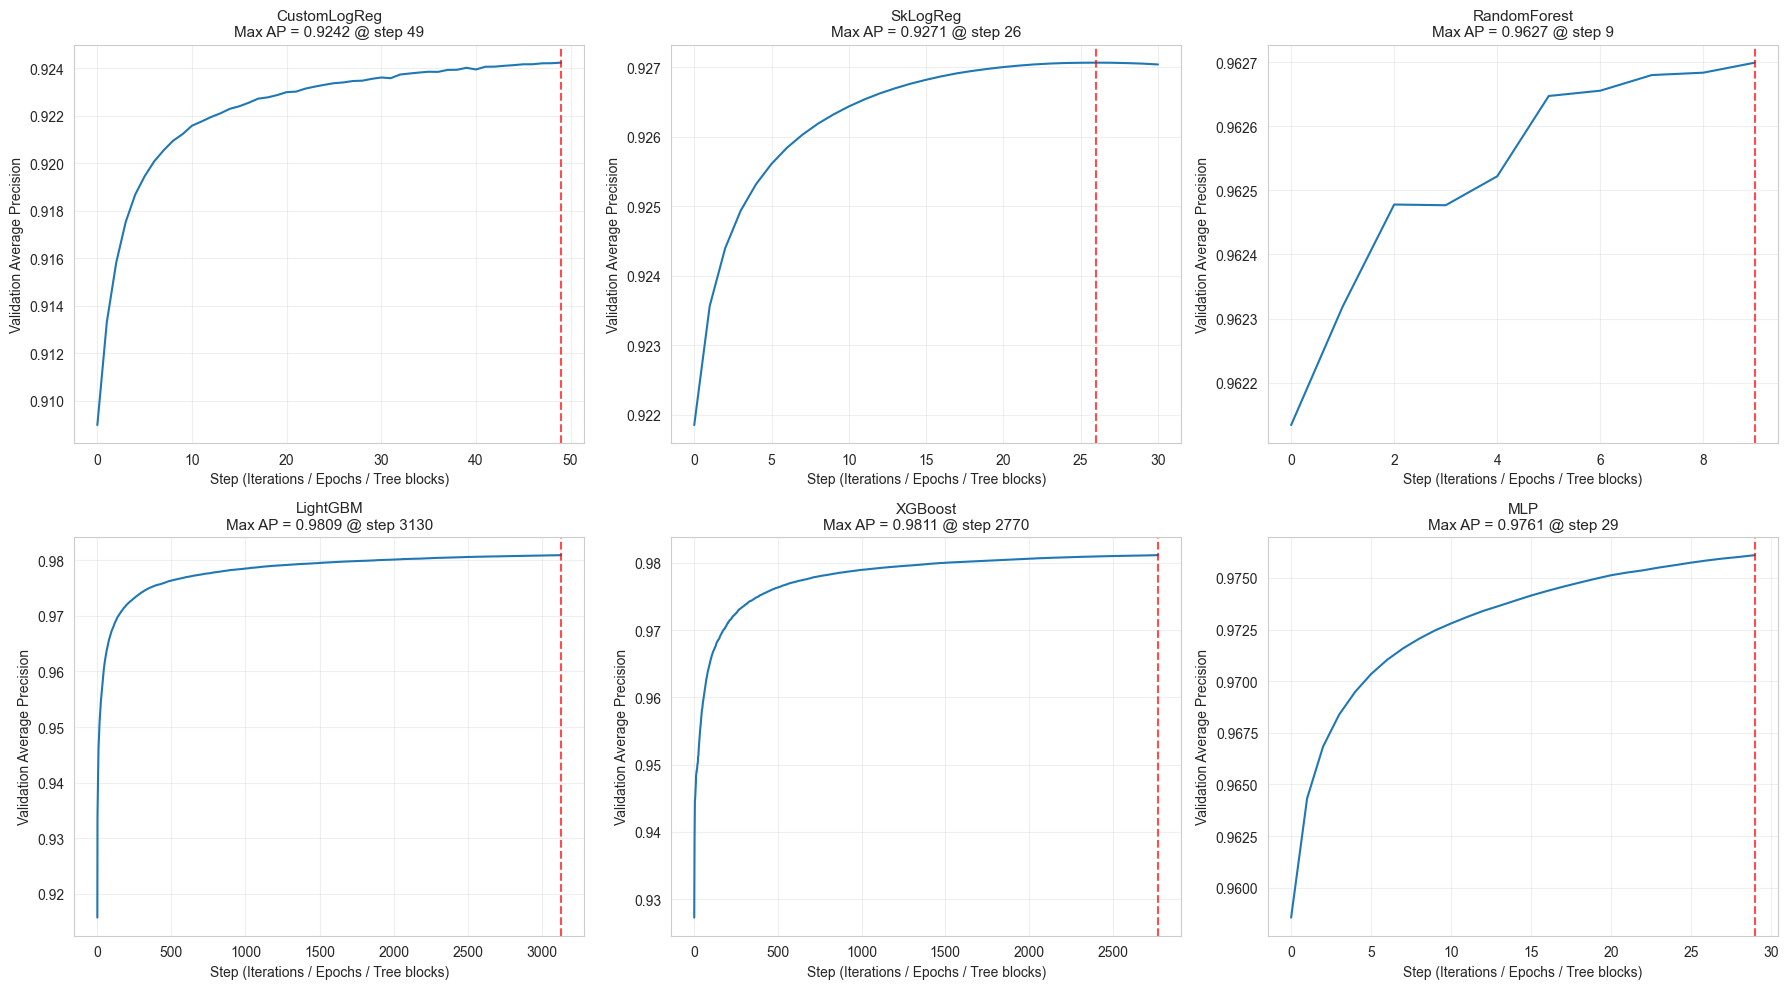

In [86]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, hist) in enumerate(eval_histories.items()):
    ax = axes[i]
    ap = hist["valid_0"]["average_precision"]
    best_i = int(np.argmax(ap))

    ax.plot(ap, linewidth=1.5)
    ax.axvline(best_i, color="r", ls="--", alpha=0.7)
    ax.set_title(f"{name}\nMax AP = {ap[best_i]:.4f} @ step {best_i}", fontsize=11)
    ax.set_xlabel("Step (Iterations / Epochs / Tree blocks)")
    ax.set_ylabel("Validation Average Precision")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{PATHS['plots_dir']}/val_ap_all_models.png", dpi=140)
plt.show()

8.1

In [87]:
def pick_threshold(y_val, y_prob, target_fpr=1e-3):
    """Максимизирует TPR при FPR <= target_fpr. Возвращает (thr, fpr@thr, tpr@thr)."""
    fpr, tpr, thr = roc_curve(y_val, y_prob)
    valid = fpr <= target_fpr
    if not valid.any():
        return 0.5, None, None
    idx = np.argmax(tpr * valid)
    return float(thr[idx]), float(fpr[idx]), float(tpr[idx])


def pick_threshold_at_recall(y_val, y_prob, target_recall=0.95):
    _, r, thr = precision_recall_curve(y_val, y_prob)
    idx = np.searchsorted(-r, -target_recall, side="right") - 1
    return float(thr[max(idx, 0)])

8.2

In [110]:
thresholds = {}  # FPR-targeted
thresholds_recall = {}  # Recall-targeted
val_probs = {}

for name, model in trained_models.items():
    Xva = get_X(name, "val")
    y_prob = model.predict_proba(Xva)
    y_prob = y_prob[:, 1] if y_prob.ndim == 2 else y_prob
    val_probs[name] = y_prob

    thr, fpr_at, tpr_at = pick_threshold(y_val, y_prob, TARGET_FPR_VAL)
    thresholds[name] = thr

    thr_rec = pick_threshold_at_recall(y_val, y_prob, target_recall=0.95)
    thresholds_recall[name] = thr_rec

    print(
        f"{name:15s} | FPR-thr={thr:.4f} (TPR={tpr_at:.3f}) | Recall-thr={thr_rec:.4f}"
    )

CustomLogReg    | FPR-thr=0.9690 (TPR=0.317) | Recall-thr=0.1738
SkLogReg        | FPR-thr=0.9769 (TPR=0.331) | Recall-thr=0.1620
RandomForest    | FPR-thr=0.9347 (TPR=0.578) | Recall-thr=0.2312
LightGBM        | FPR-thr=0.9703 (TPR=0.657) | Recall-thr=0.2863
XGBoost         | FPR-thr=0.9725 (TPR=0.660) | Recall-thr=0.2857
MLP             | FPR-thr=0.9769 (TPR=0.616) | Recall-thr=0.2469


9.1

In [89]:
def tpr_at_fpr(y_true, y_prob, target_fpr):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    idx = np.searchsorted(fpr, target_fpr, side="right") - 1
    return float(tpr[max(idx, 0)])


def precision_at_recall(y_true, y_prob, target_recall):
    p, r, _ = precision_recall_curve(y_true, y_prob)
    idx = np.searchsorted(-r, -target_recall, side="right") - 1
    return float(p[max(idx, 0)])


def fp_per_million(fpr):
    return fpr * 1_000_000


def precision_at_prevalence(tpr, fpr, prevalence):
    num = prevalence * tpr
    den = num + (1 - prevalence) * fpr
    return num / den if den > 0 else 0.0


def metrics_block(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
        "tpr": tp / (tp + fn) if tp + fn else 0.0,
        "fpr": fp / (fp + tn) if fp + tn else 0.0,
        "fp_per_million": fp_per_million(fp / (fp + tn)) if fp + tn else 0.0,
        "brier": brier_score_loss(y_true, y_prob),
    }


def per_family_recall(df_test, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    out = {}
    for fam in df_test.loc[df_test["label"] == 1, "class"].unique():
        m = (df_test["class"] == fam).to_numpy()
        out[fam] = float((y_pred[m] == 1).mean())
    return out

9.2

In [111]:
test_probs = {"id": {}, "ood": {}}

for name, model in trained_models.items():
    for split in ("id", "ood"):
        Xte = get_X(name, f"test_{split}")
        p = model.predict_proba(Xte)
        p = p[:, 1] if p.ndim == 2 else p
        test_probs[split][name] = p

print("probs computed:")
for split in ("id", "ood"):
    for name in test_probs[split]:
        print(f"  {split:3s} | {name:15s} | mean={test_probs[split][name].mean():.4f}")

probs computed:
  id  | CustomLogReg    | mean=0.4531
  id  | SkLogReg        | mean=0.4573
  id  | RandomForest    | mean=0.4539
  id  | LightGBM        | mean=0.4533
  id  | XGBoost         | mean=0.4533
  id  | MLP             | mean=0.4491
  ood | CustomLogReg    | mean=0.4996
  ood | SkLogReg        | mean=0.4992
  ood | RandomForest    | mean=0.4717
  ood | LightGBM        | mean=0.4737
  ood | XGBoost         | mean=0.4729
  ood | MLP             | mean=0.4831


9.3

In [91]:
rows = []
for name in trained_models:
    m = metrics_block(y_test_id, test_probs["id"][name], thresholds[name])
    m["model"] = name
    m["tpr@fpr=1e-2"] = tpr_at_fpr(y_test_id, test_probs["id"][name], 1e-2)
    m["tpr@fpr=1e-3"] = tpr_at_fpr(y_test_id, test_probs["id"][name], 1e-3)
    m["tpr@fpr=1e-4"] = tpr_at_fpr(y_test_id, test_probs["id"][name], 1e-4)
    for r in TARGET_RECALLS:
        m[f"prec@rec={r}"] = precision_at_recall(y_test_id, test_probs["id"][name], r)
    for prev in REALISTIC_PREVALENCES:
        m[f"prec@prev={prev}"] = precision_at_prevalence(m["tpr"], m["fpr"], prev)
    rows.append(m)

metrics_id = pd.DataFrame(rows).set_index("model")
cols = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc",
    "tpr",
    "fpr",
    "fp_per_million",
    "brier",
    "tpr@fpr=1e-2",
    "tpr@fpr=1e-3",
    "tpr@fpr=1e-4",
    "prec@rec=0.95",
    "prec@rec=0.99",
    "prec@prev=0.001",
    "prec@prev=0.0001",
]
print("=== test_id ===")
print(metrics_id[cols].round(5).to_string())

=== test_id ===
              accuracy  precision   recall       f1  roc_auc   pr_auc      tpr      fpr  fp_per_million    brier  tpr@fpr=1e-2  tpr@fpr=1e-3  tpr@fpr=1e-4  prec@rec=0.95  prec@rec=0.99  prec@prev=0.001  prec@prev=0.0001
model                                                                                                                                                                                                                      
CustomLogReg   0.69116    0.99586  0.32061  0.48505  0.92278  0.92314  0.32061  0.00111      1106.73307  0.10873       0.56129       0.30131       0.08129        0.64362        0.55774          0.22479           0.02816
SkLogReg       0.69660    0.99546  0.33279  0.49882  0.92565  0.92598  0.33279  0.00126      1260.07560  0.10665       0.56759       0.30404       0.08657        0.64812        0.56301          0.20909           0.02573
RandomForest   0.80739    0.99769  0.57680  0.73099  0.96377  0.96236  0.57680  0.00111      1106.73307 

9.4

In [92]:
rows = []
for name in trained_models:
    m = metrics_block(y_test_ood, test_probs["ood"][name], thresholds[name])
    m["model"] = name
    m["tpr@fpr=1e-2"] = tpr_at_fpr(y_test_ood, test_probs["ood"][name], 1e-2)
    m["tpr@fpr=1e-3"] = tpr_at_fpr(y_test_ood, test_probs["ood"][name], 1e-3)
    m["tpr@fpr=1e-4"] = tpr_at_fpr(y_test_ood, test_probs["ood"][name], 1e-4)
    for r in TARGET_RECALLS:
        m[f"prec@rec={r}"] = precision_at_recall(y_test_ood, test_probs["ood"][name], r)
    for prev in REALISTIC_PREVALENCES:
        m[f"prec@prev={prev}"] = precision_at_prevalence(m["tpr"], m["fpr"], prev)
    rows.append(m)

metrics_ood = pd.DataFrame(rows).set_index("model")
print("=== test_ood (novel families) ===")
print(metrics_ood[cols].round(5).to_string())

=== test_ood (novel families) ===
              accuracy  precision   recall       f1  roc_auc   pr_auc      tpr      fpr  fp_per_million    brier  tpr@fpr=1e-2  tpr@fpr=1e-3  tpr@fpr=1e-4  prec@rec=0.95  prec@rec=0.99  prec@prev=0.001  prec@prev=0.0001
model                                                                                                                                                                                                                      
CustomLogReg   0.64143    0.99700  0.32521  0.49044  0.91546  0.93769  0.32521  0.00111      1106.73307  0.11452       0.60943       0.29692       0.05226        0.68158        0.58231          0.22729           0.02855
SkLogReg       0.63923    0.99654  0.32121  0.48583  0.91551  0.93688  0.32121  0.00126      1260.07560  0.11535       0.58984       0.27981       0.04483        0.68858        0.57604          0.20329           0.02486
RandomForest   0.74463    0.99812  0.51970  0.68351  0.92244  0.94423  0.51970  0.0011

9.5

In [93]:
fam_recalls = {}
for name in trained_models:
    fam_recalls[name] = per_family_recall(
        df_test_ood, test_probs["ood"][name], thresholds[name]
    )

fam_df = pd.DataFrame(fam_recalls)
fam_df["mean"] = fam_df.mean(axis=1)
fam_df["type"] = fam_df.index.map(
    lambda f: (
        "wordlist"
        if f
        in [
            "matsnu",
            "pizd",
            "suppobox-1",
            "suppobox-2",
            "suppobox-3",
            "vawtrak-v3",
            "gozi-nasa",
            "gozi-rfc4343",
        ]
        else "other"
    )
)
fam_df = fam_df.sort_values("mean")
print("=== per-family recall on test_ood ===")
print(fam_df.round(4).to_string())

=== per-family recall on test_ood ===
              CustomLogReg  SkLogReg  RandomForest  LightGBM  XGBoost     MLP    mean      type
suppobox-1          0.0000    0.0001        0.0000    0.0067   0.0095  0.0031  0.0032  wordlist
simda               0.0048    0.0036        0.0187    0.0887   0.0762  0.0632  0.0425     other
proslikefan         0.0778    0.0656        0.2038    0.3651   0.3705  0.3483  0.2385     other
pykspa              0.1540    0.1462        0.4330    0.6052   0.6064  0.5666  0.4186     other
fobber-v2           0.1428    0.1152        0.6911    0.7546   0.7547  0.6060  0.5107     other
shiotob             0.3922    0.4251        0.5769    0.5906   0.6065  0.7284  0.5533     other
dircrypt            0.5097    0.5060        0.7203    0.7680   0.7712  0.7592  0.6724     other
cryptolocker        0.5334    0.5299        0.7021    0.7482   0.7560  0.8192  0.6815     other
tinba               0.5319    0.5127        0.8026    0.8430   0.8428  0.8320  0.7275     other
mu

10.1

In [97]:
calibrated = {}
for name, model in trained_models.items():
    Xva = get_X(name, "val")
    # Получаем сырые вероятности на валидации
    p_val = model.predict_proba(Xva)[:, 1]

    # Обучаем изотонический калибратор
    iso_reg = IsotonicRegression(out_of_bounds="clip")
    iso_reg.fit(p_val, y_val)

    calibrated[name] = iso_reg
    print(f"{name:15s} | calibrated (IsotonicRegression)")

CustomLogReg    | calibrated (IsotonicRegression)
SkLogReg        | calibrated (IsotonicRegression)
RandomForest    | calibrated (IsotonicRegression)
LightGBM        | calibrated (IsotonicRegression)
XGBoost         | calibrated (IsotonicRegression)
MLP             | calibrated (IsotonicRegression)


10.2

In [98]:
for split in ("id", "ood"):
    Xte_split = "test_" + split
    y_split = y_test_id if split == "id" else y_test_ood
    print(f"--- {split} ---")
    for name, model in trained_models.items():
        p_raw = test_probs[split][name]
        # Калибруем сырые вероятности с помощью обученного изотоника
        p_cal = calibrated[name].predict(p_raw)
        print(
            f"{name:15s} | Brier raw={brier_score_loss(y_split, p_raw):.5f} "
            f"| cal={brier_score_loss(y_split, p_cal):.5f}"
        )

--- id ---
CustomLogReg    | Brier raw=0.10873 | cal=0.10791
SkLogReg        | Brier raw=0.10665 | cal=0.10557
RandomForest    | Brier raw=0.07596 | cal=0.07460
LightGBM        | Brier raw=0.05176 | cal=0.05169
XGBoost         | Brier raw=0.05150 | cal=0.05145
MLP             | Brier raw=0.05857 | cal=0.05855
--- ood ---
CustomLogReg    | Brier raw=0.11452 | cal=0.11362
SkLogReg        | Brier raw=0.11535 | cal=0.11509
RandomForest    | Brier raw=0.11156 | cal=0.11282
LightGBM        | Brier raw=0.09107 | cal=0.09131
XGBoost         | Brier raw=0.09231 | cal=0.09243
MLP             | Brier raw=0.08677 | cal=0.08617


10.3

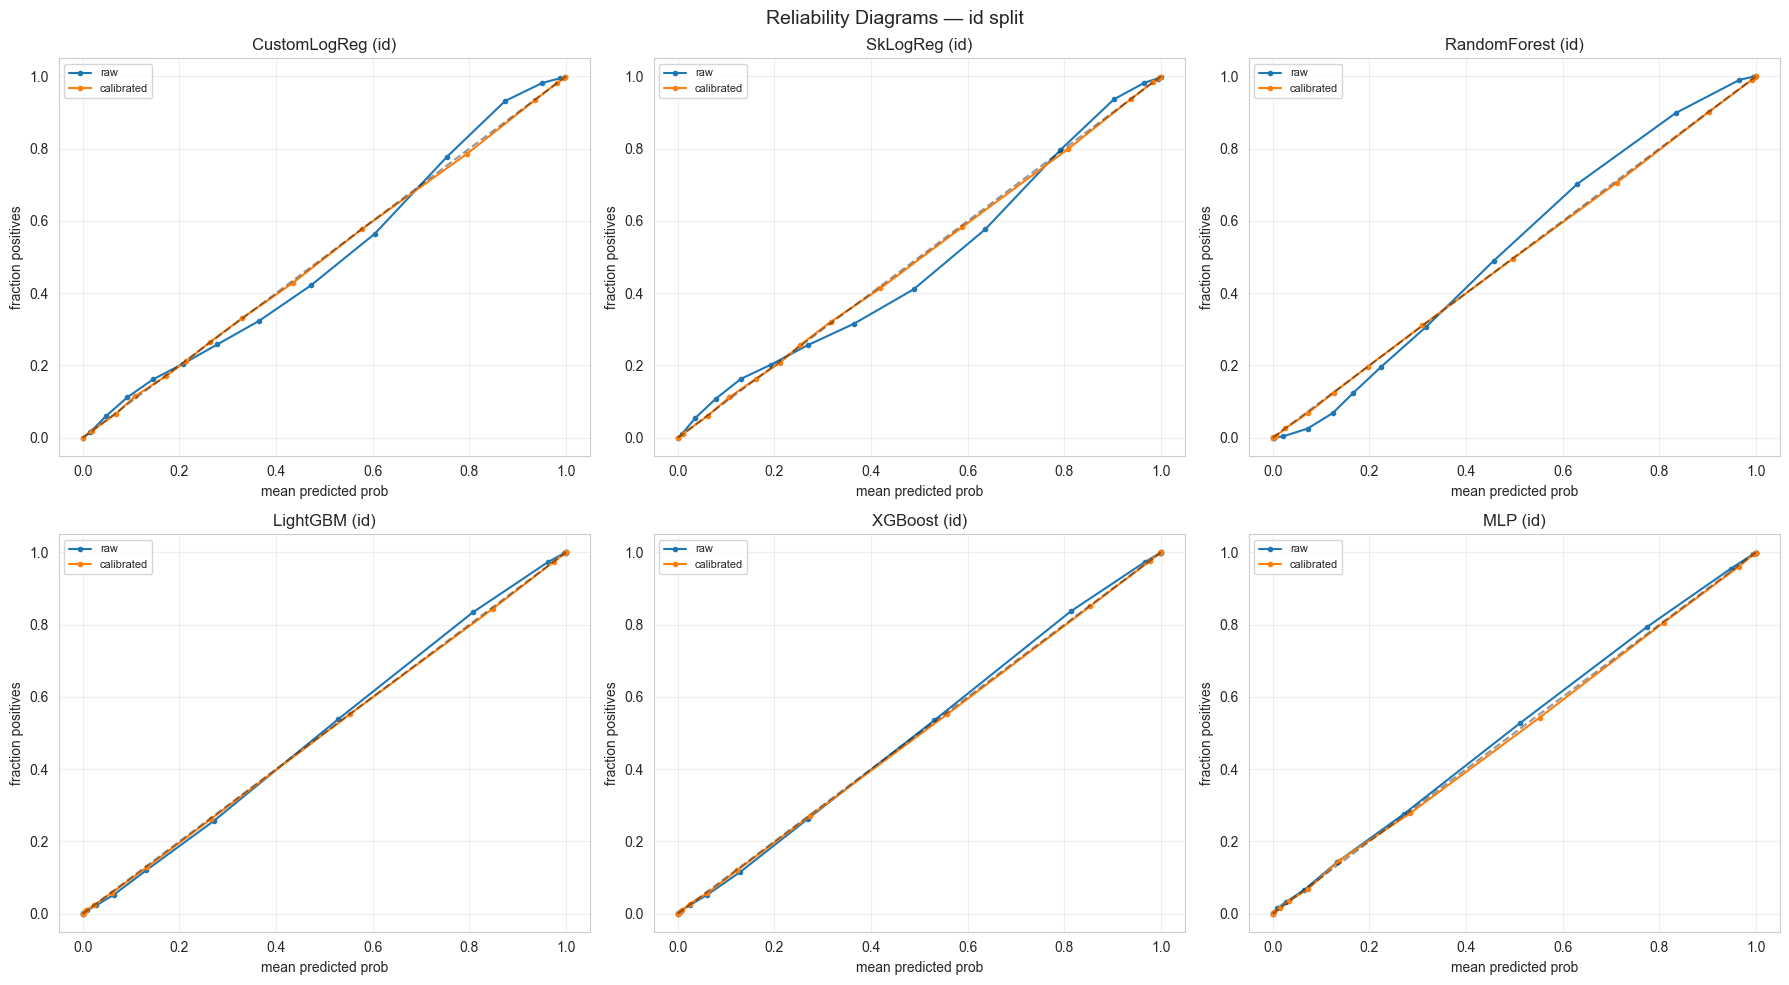

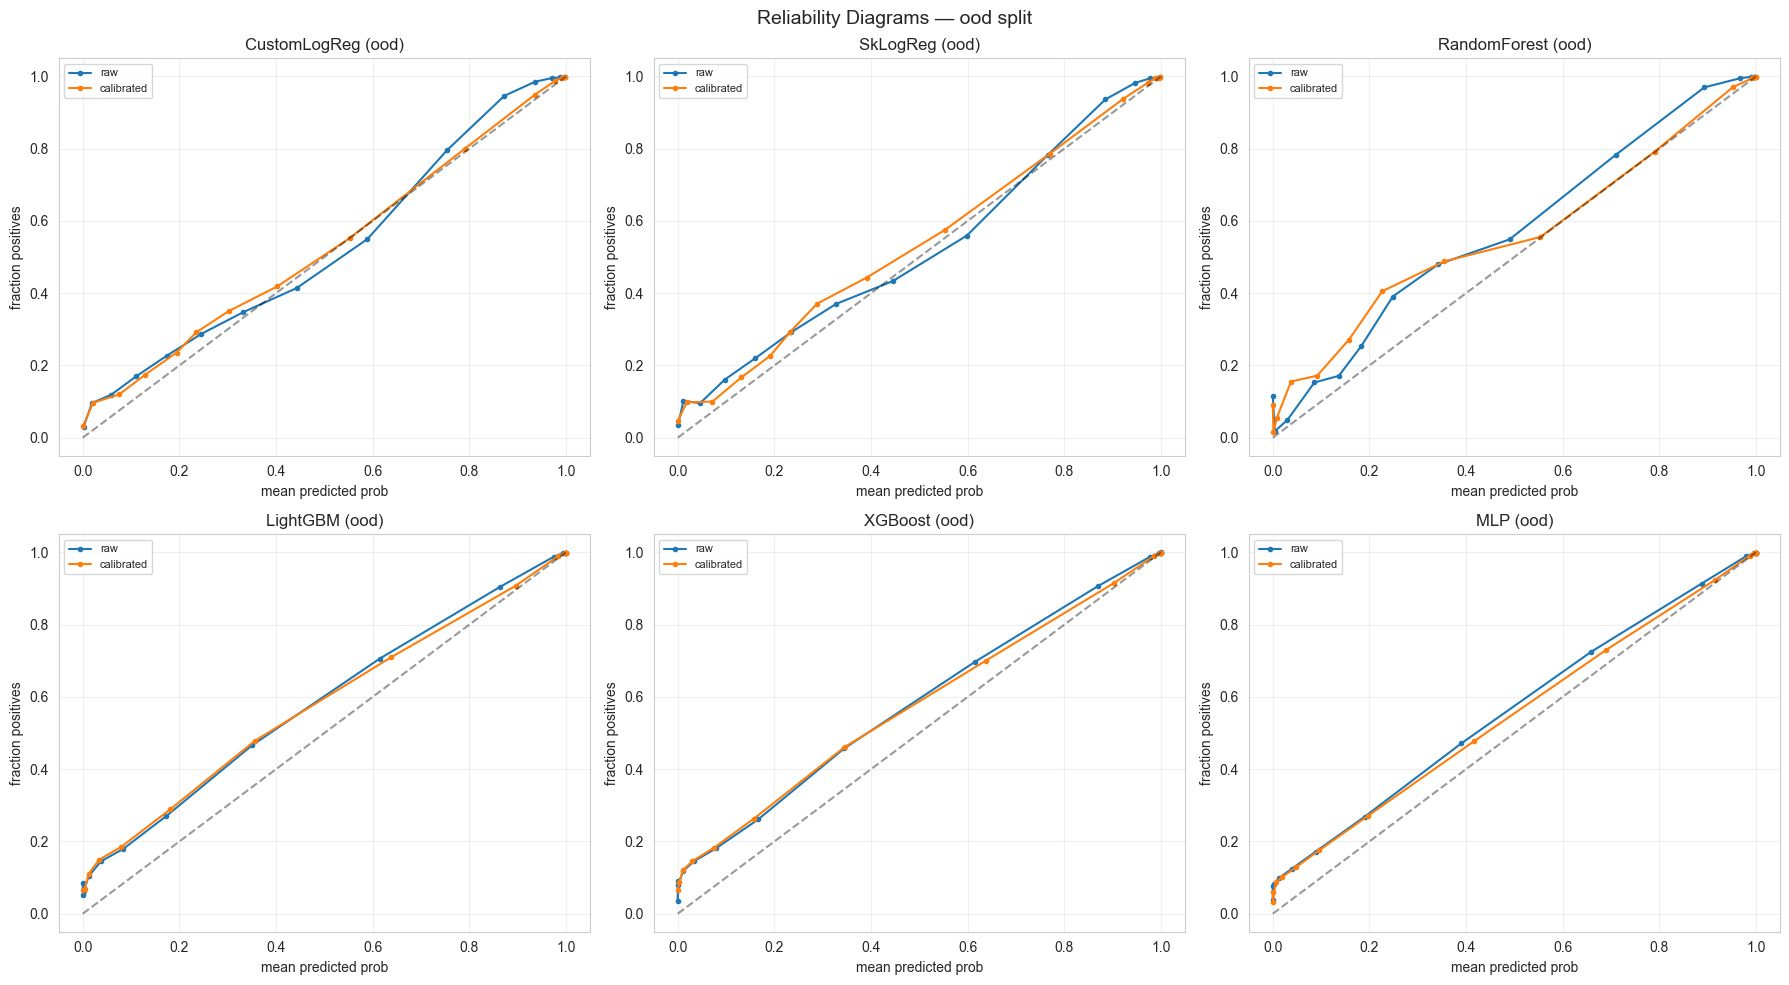

In [99]:
for split in ["id", "ood"]:
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    for i, name in enumerate(trained_models.keys()):
        ax = axes[i]
        y_true = y_test_id if split == "id" else y_test_ood
        p_raw = test_probs[split][name]
        p_cal = calibrated[name].predict(p_raw)  # Используем новый калибратор

        for label, p in [("raw", p_raw), ("calibrated", p_cal)]:
            frac_pos, mean_pred = calibration_curve(
                y_true, p, n_bins=15, strategy="quantile"
            )
            ax.plot(mean_pred, frac_pos, marker=".", label=label)

        ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
        ax.set_title(f"{name} ({split})")
        ax.set_xlabel("mean predicted prob")
        ax.set_ylabel("fraction positives")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)

    plt.suptitle(f"Reliability Diagrams — {split} split", fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{PATHS['plots_dir']}/reliability_all_{split}.png", dpi=140)
    plt.show()

11.1

In [100]:
print("=== Native Feature Importances ===")

native_results = {}

for name, model in trained_models.items():
    print(f"\n--- {name} ---")

    if name == "LightGBM":
        imp = pd.Series(
            model.booster_.feature_importance(importance_type="gain"),
            index=feature_cols_final,
        )
    elif name in ["XGBoost", "RandomForest"]:
        imp = pd.Series(model.feature_importances_, index=feature_cols_final)
    elif name in ["SkLogReg", "CustomLogReg"]:
        # Для логистических регрессий важность = модуль весов (без bias)
        coef = model.coef_[0] if name == "SkLogReg" else model.weights[1:]
        imp = pd.Series(np.abs(coef), index=feature_cols_final)
    elif name == "MLP":
        print("Native feature importance is not directly available for MLP.")
        continue

    native_results[name] = imp.sort_values(ascending=False)
    print(imp.sort_values(ascending=False).head(50).round(4).to_string())

=== Native Feature Importances ===

--- CustomLogReg ---
nlp_1g_dst_em     1.3972
nlp_r_sym_fqdn    1.0762
nlp_3g_pro        1.0536
nlp_2g_e          1.0255
nlp_3g_tstd       0.9918
nlp_3g_tpstd      0.9918
nlp_2g_dst_em     0.8296
nlp_l_odn         0.7983
nlp_lc_c          0.7323
nlp_1g_tsum       0.6985
nlp_lc_n          0.6903
nlp_2g_tsum       0.6763
nlp_3g_tkur       0.6200
nlp_r_sym_2dn     0.5748
nlp_3g_tsum       0.5674
nlp_2g_tstd       0.5243
nlp_2g_tpstd      0.5243
nlp_1g_sumsq      0.4931
nlp_r_num_fqdn    0.4911
nlp_1g_e          0.4823
nlp_2g_tsumsq     0.4725
nlp_1g_ske        0.4717
nlp_2g_pea        0.4627
nlp_2g_tvar       0.4522
nlp_2g_tpvar      0.4522
nlp_3g_dst_ch     0.4382
nlp_3g_dst_em     0.4068
nlp_1g_norm       0.4022
nlp_3g_var        0.3856
nlp_3g_pvar       0.3856
nlp_l_2dn         0.3825
nlp_3g_norm       0.3802
nlp_1g_pro        0.3475
nlp_r_con_odn     0.3437
nlp_1g_ken        0.3391
nlp_1g_tske       0.3190
nlp_1g_kur        0.3173
nlp_1g_rep        

11.2

In [105]:
print("=== Permutation Importance ===")

# Берем подвыборку для скорости
rng = np.random.RandomState(SEED)
perm_idx = rng.choice(len(X_val), size=5000, replace=False)
y_perm = y_val.iloc[perm_idx]

perm_results = {}

for name, model in trained_models.items():
    print(f"\n--- {name} ---")
    # Используем правильный X (scaled или raw) в зависимости от модели
    X_perm = X_val_s.iloc[perm_idx] if MODELS[name]["scale"] else X_val.iloc[perm_idx]

    perm = permutation_importance(
        model,
        X_perm,
        y_perm,
        scoring="average_precision",
        n_repeats=3,
        random_state=SEED,
        n_jobs=-1,
    )
    perm_series = pd.Series(
        perm.importances_mean, index=feature_cols_final
    ).sort_values(ascending=False)
    perm_results[name] = perm_series

    print(perm_series.sort_values(ascending=False).head(50).round(4).to_string())

=== Permutation Importance ===

--- CustomLogReg ---
nlp_1g_dst_em     0.0986
nlp_r_sym_fqdn    0.0592
nlp_2g_e          0.0540
nlp_3g_pro        0.0508
nlp_3g_tstd       0.0447
nlp_3g_tpstd      0.0447
nlp_lc_c          0.0313
nlp_l_odn         0.0268
nlp_2g_tsum       0.0240
nlp_2g_dst_em     0.0236
nlp_1g_tsum       0.0220
nlp_3g_tkur       0.0212
nlp_3g_tsum       0.0201
nlp_2g_tsumsq     0.0143
nlp_lc_n          0.0140
nlp_2g_tpstd      0.0137
nlp_2g_tstd       0.0137
nlp_2g_tpvar      0.0133
nlp_2g_tvar       0.0133
nlp_1g_ske        0.0129
nlp_1g_sumsq      0.0116
nlp_1g_e          0.0114
nlp_r_num_fqdn    0.0105
nlp_r_sym_2dn     0.0104
nlp_2g_pea        0.0074
nlp_1g_pro        0.0072
nlp_r_con_odn     0.0070
nlp_3g_dst_em     0.0066
nlp_3g_norm       0.0063
nlp_l_2dn         0.0063
nlp_1g_norm       0.0061
nlp_3g_dst_ch     0.0061
nlp_3g_tsumsq     0.0048
nlp_3g_tpvar      0.0048
nlp_3g_tvar       0.0048
nlp_3g_var        0.0044
nlp_3g_pvar       0.0044
nlp_r_con_2dn     0.00

11.3

In [112]:
print("=== SHAP Values ===")

rng = np.random.RandomState(SEED)

shap_results = {}

# Для MLP (KernelSHAP) берем мало примеров
idx_small = rng.choice(len(X_val), size=500, replace=False)
idx_large = rng.choice(len(X_val), size=5000, replace=False)

for name, model in trained_models.items():
    print(f"\n--- {name} ---")

    if name in ["LightGBM", "XGBoost", "RandomForest"]:
        X_shap = X_val.iloc[idx_large]
        explainer = shap.TreeExplainer(model)
        shap_vals = explainer.shap_values(X_shap)

    elif name in ["SkLogReg", "CustomLogReg"]:
        X_shap = (
            X_val_s.iloc[idx_large] if MODELS[name]["scale"] else X_val.iloc[idx_large]
        )
        # Для логрегов используем LinearExplainer на фоне всех данных (или их среза)
        masker = shap.maskers.Independent(X_shap, max_samples=100)
        explainer = shap.LinearExplainer(model, masker)
        shap_vals = explainer.shap_values(X_shap)

    elif name == "MLP":
        X_shap = X_val_s.iloc[idx_small]
        print(
            f"  (Using KernelSHAP on {len(X_shap)} samples, this may take a minute...)"
        )
        # Фоновый набор для MLP
        background = shap.sample(X_val_s, 50)
        explainer = shap.KernelExplainer(model.predict_proba, background)
        shap_vals = explainer.shap_values(X_shap, nsamples=100)

    # Обработка формата вывода (бинарная классификация)
    if isinstance(shap_vals, list):
        shap_vals = shap_vals[1]
    elif (
        len(shap_vals.shape) == 3
    ):  # Некоторые версии возвращают (n, features, classes)
        shap_vals = shap_vals[:, :, 1]

    shap_series = pd.Series(
        np.abs(shap_vals).mean(axis=0), index=feature_cols_final
    ).sort_values(ascending=False)
    shap_results[name] = shap_series

    print(shap_series.sort_values(ascending=False).head(50).round(4).to_string())

Background dataset has 5000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5000 when initializing the masker.


Background dataset has 5000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5000 when initializing the masker.


=== SHAP Values ===

--- CustomLogReg ---
nlp_1g_dst_em     1.1447
nlp_r_sym_fqdn    0.7783
nlp_2g_e          0.7606
nlp_2g_dst_em     0.6822
nlp_3g_pro        0.6003
nlp_1g_tsum       0.5673
nlp_lc_c          0.5563
nlp_3g_tkur       0.5527
nlp_2g_tsum       0.5101
nlp_3g_tstd       0.4902
nlp_3g_tpstd      0.4902
nlp_lc_n          0.4373
nlp_2g_tstd       0.4258
nlp_2g_tpstd      0.4258
nlp_l_odn         0.3801
nlp_1g_e          0.3689
nlp_1g_ske        0.3656
nlp_2g_pea        0.3615
nlp_1g_norm       0.3574
nlp_1g_sumsq      0.3543
nlp_r_num_fqdn    0.3422
nlp_3g_dst_em     0.3411
nlp_3g_tsum       0.3375
nlp_2g_tsumsq     0.3319
nlp_2g_tvar       0.3180
nlp_2g_tpvar      0.3180
nlp_l_2dn         0.3002
nlp_3g_dst_ch     0.2884
nlp_1g_ken        0.2670
nlp_1g_pro        0.2649
nlp_3g_var        0.2511
nlp_3g_pvar       0.2511
nlp_1g_rep        0.2506
nlp_3g_norm       0.2474
nlp_1g_tske       0.2374
nlp_1g_kur        0.2304
nlp_r_sym_2dn     0.2177
nlp_1g_dst_kl     0.2162
nlp_2g_c

c:\Users\pc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


nlp_l_2dn         1.3617
nlp_3g_e          1.3295
nlp_3g_norm       0.7784
nlp_1g_dst_em     0.7611
nlp_lc_c          0.7195
nlp_2g_norm       0.5460
nlp_r_sym_fqdn    0.4879
nlp_2g_e          0.4834
nlp_2g_dst_em     0.4665
nlp_r_con_2dn     0.4540
nlp_3g_tpstd      0.4070
nlp_r_let_fqdn    0.3788
nlp_3g_dst_eu     0.3677
nlp_3g_dst_em     0.3113
nlp_3g_ken        0.2897
nlp_1g_norm       0.2880
nlp_1g_dst_ca     0.2641
nlp_r_vow_fqdn    0.2583
nlp_r_con_fqdn    0.2384
nlp_r_vow_2dn     0.2194
nlp_3g_pstd       0.2140
nlp_3g_tsumsq     0.2086
nlp_3g_dst_ca     0.2041
nlp_2g_tpstd      0.2038
nlp_2g_dst_eu     0.1935
nlp_lc_n          0.1765
nlp_1g_tpstd      0.1662
nlp_1g_tske       0.1617
nlp_3g_tkur       0.1600
nlp_lc_v          0.1577
nlp_3g_tpvar      0.1544
nlp_2g_tsumsq     0.1540
nlp_1g_tkur       0.1456
nlp_2g_pro        0.1449
nlp_l_fqdn        0.1342
nlp_2g_tkur       0.1308
nlp_3g_ske        0.1291
nlp_3g_pro        0.1268
nlp_2g_tsum       0.1253
nlp_r_num_fqdn    0.1212


  0%|          | 0/500 [00:00<?, ?it/s]

c:\Users\pc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\shap\explainers\_kernel.py:788: UserWarning: Linear regression equation is singular, a least squares solutions is used instead.
To avoid this situation and get a regular matrix do one of the following:
1) turn up the number of samples,
2) turn up the L1 regularization with num_features(N) where N is less than the number of samples,
3) group features together to reduce the number of inputs that need to be explained.
  warnings.warn(


nlp_3g_e          0.0563
nlp_2g_e          0.0485
nlp_l_odn         0.0410
nlp_1g_dst_em     0.0371
nlp_r_sym_fqdn    0.0274
nlp_2g_dst_em     0.0228
nlp_r_num_fqdn    0.0219
nlp_l_2dn         0.0136
nlp_1g_tsum       0.0126
nlp_r_num_2dn     0.0098
nlp_3g_tstd       0.0097
nlp_lc_c          0.0096
nlp_2g_pea        0.0095
nlp_r_let_2dn     0.0094
nlp_r_vow_odn     0.0093
nlp_lc_n          0.0080
nlp_3g_dst_eu     0.0075
nlp_2g_tpstd      0.0071
nlp_3g_norm       0.0071
nlp_3g_tpstd      0.0069
nlp_r_sym_2dn     0.0063
nlp_r_let_fqdn    0.0063
nlp_3g_dst_em     0.0061
nlp_3g_cov        0.0060
nlp_1g_e          0.0057
nlp_2g_pro        0.0057
nlp_1g_tske       0.0056
nlp_1g_dst_ca     0.0056
nlp_3g_dst_kl     0.0055
nlp_3g_pvar       0.0054
nlp_2g_tsumsq     0.0054
nlp_2g_pstd       0.0053
nlp_3g_tsum       0.0053
nlp_2g_spe        0.0052
nlp_2g_tstd       0.0051
nlp_n             0.0051
nlp_1g_tsumsq     0.0051
nlp_2g_tvar       0.0051
nlp_3g_pstd       0.0048
nlp_3g_dst_ji     0.0046


11.4

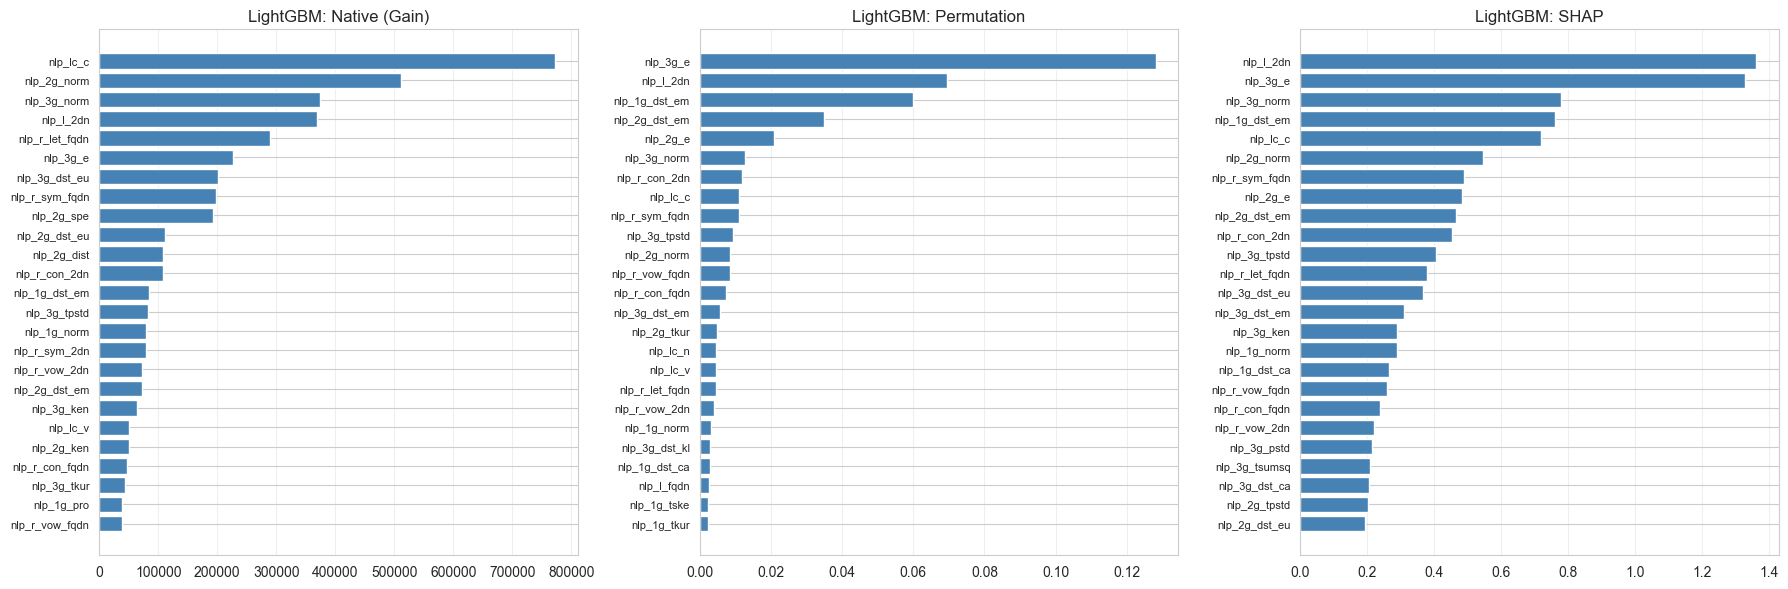

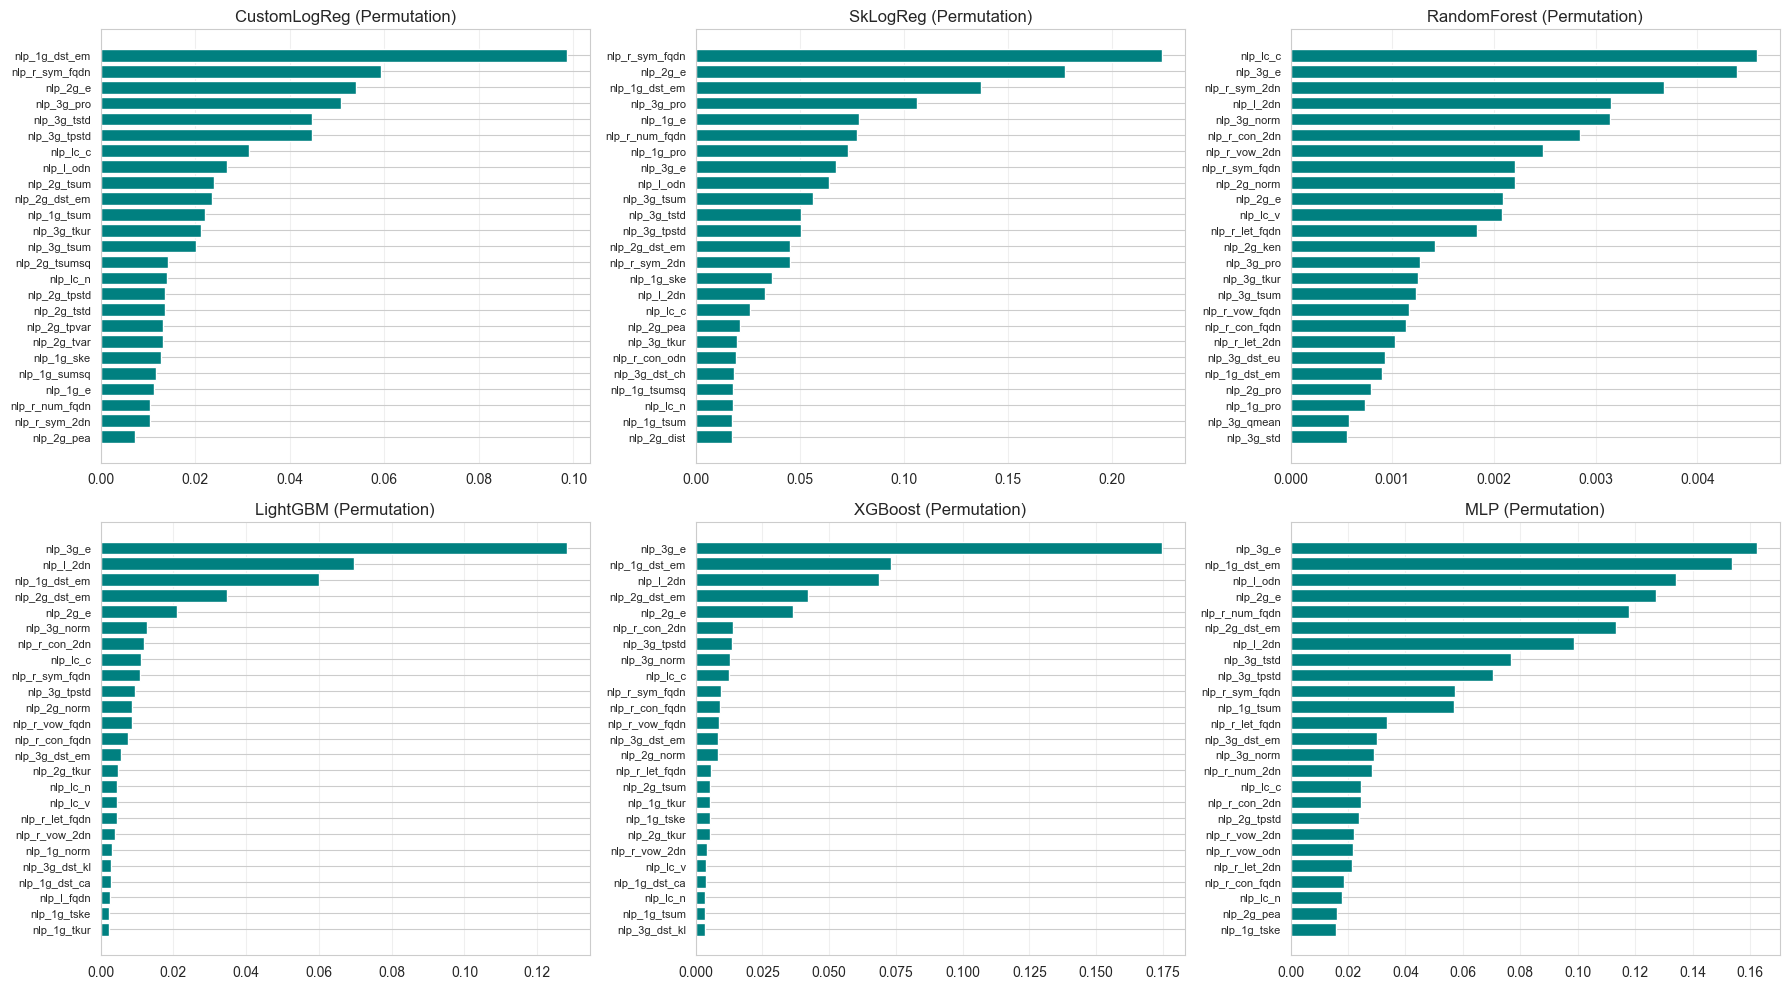

=== Consensus Analysis ===
Признаки, входящие в Топ-25 у ВСЕХ 6 моделей (по Permutation): 4
['nlp_r_sym_fqdn', 'nlp_lc_c', 'nlp_1g_dst_em', 'nlp_2g_e']

=== Матрица пересечений Топ-25 (только пары с пересечением > 10) ===
LightGBM & XGBoost: 23
CustomLogReg & SkLogReg: 18
XGBoost & MLP: 17
LightGBM & MLP: 16
SkLogReg & MLP: 14
RandomForest & LightGBM: 14
RandomForest & XGBoost: 14
CustomLogReg & MLP: 13
RandomForest & MLP: 12
SkLogReg & RandomForest: 11
SkLogReg & XGBoost: 10


In [113]:
# Сравнение методов на примере LightGBM
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
model_name = "LightGBM"

for ax, (title, results) in zip(
    axes,
    [
        ("Native (Gain)", native_results.get(model_name)),
        ("Permutation", perm_results.get(model_name)),
        ("SHAP", shap_results.get(model_name)),
    ],
):
    if results is not None:
        top = results.head(25)[::-1]
        ax.barh(range(len(top)), top.values, color="steelblue")
        ax.set_yticks(range(len(top)))
        ax.set_yticklabels(top.index, fontsize=8)
        ax.set_title(f"{model_name}: {title}")
        ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    f"{PATHS['plots_dir']}/importance_method_comparison_{model_name}.png", dpi=140
)
plt.show()

# Топ-25 Permutation Importance для всех моделей
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, s) in enumerate(perm_results.items()):
    ax = axes[i]
    top = s.head(25)[::-1]
    ax.barh(range(len(top)), top.values, color="teal")
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top.index, fontsize=8)
    ax.set_title(f"{name} (Permutation)")
    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(f"{PATHS['plots_dir']}/permutation_all_models.png", dpi=140)
plt.show()

# 3. Пересечение топ-20 (Consensus Table)
sets = {name: set(s.head(25).index) for name, s in perm_results.items()}
common_all = set.intersection(*sets.values())

print("=== Consensus Analysis ===")
print(
    f"Признаки, входящие в Топ-25 у ВСЕХ 6 моделей (по Permutation): {len(common_all)}"
)
print(list(common_all))

# Матрица пересечений
import itertools

intersections = {}
for m1, m2 in itertools.combinations(perm_results.keys(), 2):
    intersections[f"{m1} & {m2}"] = len(sets[m1] & sets[m2])

print("\n=== Матрица пересечений Топ-25 (только пары с пересечением > 10) ===")
for pair, count in sorted(intersections.items(), key=lambda x: x[1], reverse=True):
    if count >= 10:
        print(f"{pair}: {count}")

12.1

In [114]:
def top_errors(model_name, split="ood", n=15):
    y_true = y_test_ood if split == "ood" else y_test_id
    df = df_test_ood if split == "ood" else df_test_id
    p = test_probs[split][model_name]
    pred = (p >= thresholds[model_name]).astype(int)

    fp_mask = (y_true.to_numpy() == 0) & (pred == 1)
    fn_mask = (y_true.to_numpy() == 1) & (pred == 0)

    fp = (
        df.loc[fp_mask, ["domain", "class"]]
        .assign(prob=p[fp_mask])
        .sort_values("prob", ascending=False)
    )
    fn = (
        df.loc[fn_mask, ["domain", "class"]]
        .assign(prob=p[fn_mask])
        .sort_values("prob", ascending=True)
    )

    print(f"\n=== {model_name} ({split}) ===")
    print(f"FP count = {len(fp)} | FN count = {len(fn)}")
    print("\nTop FP (most confident, worst):")
    print(fp.head(n).to_string(index=False))
    print("\nTop FN (most confident, worst):")
    print(fn.head(n).to_string(index=False))
    return fp, fn


all_errors = {}
for name in trained_models:
    fp, fn = top_errors(name, "ood", n=10)
    all_errors[name] = {"FP": fp, "FN": fn}


=== CustomLogReg (ood) ===
FP count = 166 | FN count = 114415

Top FP (most confident, worst):
                                                      domain class     prob
omgomgomg5j4yrr4mjdv3h5c5xfvxtqqs2in7smi65mjps7wvkmqmtqd.com legit 0.999997
            xn-----6kcdfldbfd2aga1bqjlbbb4b4d7d1fzd.xn--p1ai legit 0.999957
                                        jxpxkyjtyxzrgszyy.cn legit 0.999946
                        xn-----7kchclcsdcvgr8afcd9cqkh2f.com legit 0.999819
                          xn--b1aedfedwqbdfbnzkf0oe.xn--p1ai legit 0.999696
                              xn--vk1b87o4zefwd.xn--3e0b707e legit 0.999417
                                 xn--hy1bv1e8tk46a75kztd.com legit 0.999304
                  xn--80abacdnj3a5afcccbrk3g3a2gd7d.xn--p1ai legit 0.999259
                             xn--980bx8aa741fo5glrhi5eh1b.kr legit 0.999150
                            xn--9z2b23n2e4a724cgvlx0h23g.com legit 0.998939

Top FN (most confident, worst):
  domain class         prob
qeqeq.e

12.2

In [115]:
fn_summary = pd.DataFrame()

for name in trained_models:
    # Получаем предсказания для каждой модели на test_ood
    preds = (test_probs["ood"][name] >= thresholds[name]).astype(int)
    # Находим ложноотрицательные (пропущенные DGA)
    fn_mask = (df_test_ood["label"] == 1) & (preds == 0)

    fn_fams = df_test_ood.loc[fn_mask, "class"].value_counts()
    fn_summary[name] = fn_fams

fn_summary = fn_summary.fillna(0).astype(int)

fn_summary["Total_FN_All_Models"] = fn_summary.sum(axis=1)
fn_summary = fn_summary.sort_values("Total_FN_All_Models", ascending=False)

print("=== False Negatives by Family (test_ood) ===")
print(fn_summary.to_string())

# Примеры доменов из самого проблемного семейства
worst_family = fn_summary.index[0]
print(f"\nПримеры доменов из самого сложного семейства ({worst_family}):")
samples = df_test_ood[df_test_ood["class"] == worst_family]["domain"].head(10).tolist()
print(samples)

=== False Negatives by Family (test_ood) ===
              CustomLogReg  SkLogReg  RandomForest  LightGBM  XGBoost    MLP  Total_FN_All_Models
class                                                                                            
simda                19903     19929         19626     18227    18476  18735               114896
proslikefan          18444     18689         15923     12697    12590  13034                91377
fobber-v2            17143     17696          6179      4909     4906   7881                58714
suppobox-1            9556      9555          9556      9492     9465   9526                57150
shiotob              12156     11498          8462      8189     7870   5431                53606
dircrypt              9807      9879          5594      4639     4577   4817                39313
cryptolocker          9331      9402          5958      5037     4880   3616                38224
pykspa                8460      8538          5670      3948     3936   4

13.1

In [116]:
def benchmark_single(model, X_one, n_warm=50, n=1000):
    for _ in range(n_warm):
        model.predict_proba(X_one)
    t0 = time.perf_counter()
    for _ in range(n):
        model.predict_proba(X_one)
    return (time.perf_counter() - t0) / n * 1000  # ms


def benchmark_batch(model, X_batch, n_warm=5, n=20):
    for _ in range(n_warm):
        model.predict_proba(X_batch)
    t0 = time.perf_counter()
    for _ in range(n):
        model.predict_proba(X_batch)
    return (time.perf_counter() - t0) / n  # s


latency = {}
for name, model in trained_models.items():
    Xte = get_X(name, "test_ood")
    X_one = Xte.iloc[:1]
    X_batch = Xte.iloc[:1024]

    ms_single = benchmark_single(model, X_one)
    s_batch = benchmark_batch(model, X_batch)

    _buf = io.BytesIO()
    joblib.dump(model, _buf)
    _size_mb = _buf.tell() / 1e6
    del _buf

    latency[name] = {
        "single_ms": ms_single,
        "batch_1024_s": s_batch,
        "throughput_domains_s": 1024 / s_batch,
        "model_size_mb": _size_mb,
    }
    print(
        f"{name:15s} | single={ms_single:7.3f} ms | batch1024={s_batch:6.3f} s | throughput={1024 / s_batch:8.0f} dom/s | size={latency[name]['model_size_mb']:.2f} MB"
    )

lat_df = pd.DataFrame(latency).T
print("\n=== latency summary ===")
print(lat_df.round(3).to_string())

CustomLogReg    | single=  0.035 ms | batch1024= 0.001 s | throughput= 1159854 dom/s | size=0.00 MB
SkLogReg        | single=  0.805 ms | batch1024= 0.001 s | throughput=  989831 dom/s | size=0.01 MB
RandomForest    | single= 29.162 ms | batch1024= 0.029 s | throughput=   35460 dom/s | size=68.25 MB
LightGBM        | single=  1.365 ms | batch1024= 0.017 s | throughput=   60588 dom/s | size=10.48 MB
XGBoost         | single=  4.572 ms | batch1024= 0.013 s | throughput=   79324 dom/s | size=10.41 MB
MLP             | single=  0.831 ms | batch1024= 0.020 s | throughput=   51128 dom/s | size=0.28 MB

=== latency summary ===
              single_ms  batch_1024_s  throughput_domains_s  model_size_mb
CustomLogReg      0.035         0.001           1159853.660          0.004
SkLogReg          0.805         0.001            989831.031          0.005
RandomForest     29.162         0.029             35459.685         68.254
LightGBM          1.365         0.017             60587.754         10.4

14.1

In [117]:
def cv_groupkfold(build_fn, X_full, y_full, groups, n_splits=5, target_fpr=1e-3):
    """GroupKFold по группам (семействам DGA; legit — одна группа 'legit').
    Для каждой модели возвращает mean/std ROC-AUC, PR-AUC, TPR@FPR."""
    gkf = GroupKFold(n_splits=n_splits)
    rocs, prs, tprs = [], [], []

    for fold, (tr, te) in enumerate(gkf.split(X_full, y_full, groups)):
        model = build_fn()
        model.fit(X_full.iloc[tr], y_full.iloc[tr])
        p = model.predict_proba(X_full.iloc[te])[:, 1]
        y_true = y_full.iloc[te]
        rocs.append(roc_auc_score(y_true, p))
        prs.append(average_precision_score(y_true, p))
        tprs.append(tpr_at_fpr(y_true, p, target_fpr))

    return {
        "roc_auc_mean": np.mean(rocs),
        "roc_auc_std": np.std(rocs),
        "pr_auc_mean": np.mean(prs),
        "pr_auc_std": np.std(prs),
        f"tpr@fpr{target_fpr}_mean": np.mean(tprs),
        f"tpr@fpr{target_fpr}_std": np.std(tprs),
    }

14.2

In [118]:
# CV runs on train + val + test_id (excludes OOD)
cv_idx = np.concatenate([train_idx, val_idx, test_id_idx])
X_cv = full_df.loc[cv_idx, feature_cols_final].astype("float32")
y_cv = full_df.loc[cv_idx, "label"]
g_cv = full_df.loc[cv_idx, "class"].values.astype(object).copy()

# Fix: GroupKFold needs legit split into pseudo-groups
N_LEGIT_GROUPS = 10
legit_mask = g_cv == "legit"
domain_cv = full_df.loc[cv_idx, "domain"].values
legit_hashes = pd.util.hash_array(domain_cv[legit_mask]) % N_LEGIT_GROUPS
g_cv[legit_mask] = np.array([f"legit_{h}" for h in legit_hashes])

print(
    f"GroupKFold groups: {len(np.unique(g_cv))} total "
    f"= {N_LEGIT_GROUPS} legit pseudo-groups + {len(np.unique(g_cv)) - N_LEGIT_GROUPS} DGA families"
)

# Sanity check
for g in np.unique(g_cv):
    classes = np.unique(y_cv[g_cv == g])
    assert len(classes) == 1, f"Group {g} has mixed classes {classes}"

# --- CV-specific builders ---
# These models are configured to train fully in ONE fit() call.
# This keeps CV fast and avoids warm_start loop overhead.

cv_builders = {
    "CustomLogReg": lambda: Pipeline(
        [
            ("scaler", StandardScaler()),
            ("clf", build_custom_logreg()),
        ]
    ),
    "SkLogReg": lambda: Pipeline(
        [
            ("scaler", StandardScaler()),
            (
                "clf",
                SGDClassifier(
                    loss="log_loss",
                    penalty="l2",
                    alpha=0.0001,
                    learning_rate="adaptive",
                    eta0=0.0005,
                    max_iter=100,
                    tol=1e-4,
                    average=True,
                    random_state=SEED,
                    n_jobs=-1,
                ),
            ),
        ]
    ),
    "RandomForest": lambda: RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=20,
        n_jobs=-1,
        random_state=SEED,
    ),
    "LightGBM": lambda: lgb.LGBMClassifier(
        n_estimators=2500,  # Fixed number to speed up CV (no early stopping needed)
        learning_rate=0.12,
        num_leaves=31,
        min_child_samples=200,
        feature_fraction=0.8,
        bagging_fraction=0.8,
        bagging_freq=5,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=SEED,
        verbose=-1,
        n_jobs=-1,
    ),
    "XGBoost": lambda: xgb.XGBClassifier(
        n_estimators=2500,  # Fixed number to speed up CV
        learning_rate=0.12,
        max_depth=6,
        min_child_weight=10,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        tree_method="hist",
        random_state=SEED,
        n_jobs=-1,
    ),
    # MLP removed from CV: takes 30 mins per fold, making CV last >2.5 hours.
    # Its performance can be estimated from cell 9.3/9.4.
    "MLP": lambda: Pipeline(
        [
            ("scaler", StandardScaler()),
            (
                "clf",
                MLPClassifier(
                    hidden_layer_sizes=(128,),
                    max_iter=30,
                    early_stopping=True,
                    random_state=SEED,
                ),
            ),
        ]
    ),
}

# Run CV
cv_results = {}
for name, builder in cv_builders.items():
    print(f"\nCV {name}...")
    t0 = time.perf_counter()
    cv_results[name] = cv_groupkfold(
        builder, X_cv, y_cv, g_cv, n_splits=5, target_fpr=TARGET_FPR_VAL
    )
    print(f"  done in {time.perf_counter() - t0:.1f}s")

cv_df = pd.DataFrame(cv_results).T
print("\n=== GroupKFold CV (5 folds, family-aware) ===")
print(cv_df.round(5).to_string())

del X_cv, g_cv
gc.collect()
print("X_cv freed")

GroupKFold groups: 50 total = 10 legit pseudo-groups + 40 DGA families

CV CustomLogReg...
  done in 522.0s

CV SkLogReg...
  done in 170.3s

CV RandomForest...
  done in 693.4s

CV LightGBM...
  done in 777.3s

CV XGBoost...
  done in 1232.0s

CV MLP...
  done in 8461.1s

=== GroupKFold CV (5 folds, family-aware) ===
              roc_auc_mean  roc_auc_std  pr_auc_mean  pr_auc_std  tpr@fpr0.001_mean  tpr@fpr0.001_std
CustomLogReg       0.87274      0.05851      0.87812     0.05323            0.26832           0.11111
SkLogReg           0.85987      0.06846      0.86922     0.06002            0.25468           0.10615
RandomForest       0.89589      0.04953      0.90030     0.04336            0.27840           0.14042
LightGBM           0.89408      0.05214      0.90078     0.04654            0.42321           0.10575
XGBoost            0.89441      0.05286      0.90181     0.04630            0.42736           0.09516
MLP                0.87071      0.07759      0.88576     0.06380    

15.1

In [119]:
for name, model in trained_models.items():
    joblib.dump(model, f"{PATHS['models_dir']}/{name}.pkl")
    joblib.dump(calibrated[name], f"{PATHS['models_dir']}/{name}_cal.pkl")

artifact = {
    "feature_cols": feature_cols_final,
    "base_feature_cols": feature_cols,
    "isnan_cols": isnan_cols,
    "thresholds": thresholds,
    "held_families": list(held_families),
    "target_fpr_val": TARGET_FPR_VAL,
    "seed": SEED,
    "metrics_id": metrics_id[cols].round(6).to_dict(orient="index"),
    "metrics_ood": metrics_ood[cols].round(6).to_dict(orient="index"),
    "latency": {k: {kk: float(vv) for kk, vv in v.items()} for k, v in latency.items()},
    "versions": {
        "sklearn": sklearn.__version__,
        "lightgbm": lgb.__version__,
        "xgboost": xgb.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "shap": shap.__version__,
    },
}
with open(PATHS["artifact"], "w", encoding="utf-8") as f:
    json.dump(artifact, f, ensure_ascii=False, indent=2, default=float)

print("artifact saved:", PATHS["artifact"])
print("models saved to:", PATHS["models_dir"])

artifact saved: d:\Data\Scripts\model_artifact.json
models saved to: d:\Data\Scripts\models


15.2

In [120]:
def predict_domains(
    domains_df, model_name="LightGBM", calibrated=False, feature_pipeline=None
):
    """Применение обученной модели к DataFrame с теми же признаками.
    feature_pipeline — функция предобработки (индикаторы NaN + sentinel),
    если она не была применена заранее."""
    suffix = "_cal" if calibrated else ""
    model = joblib.load(f"{PATHS['models_dir']}/{model_name}{suffix}.pkl")
    scaler_loaded = (
        joblib.load(PATHS["scaler"]) if MODELS[model_name]["scale"] else None
    )

    X = domains_df[feature_cols_final]
    if feature_pipeline:
        X = feature_pipeline(X)
    if scaler_loaded is not None:
        X = pd.DataFrame(scaler_loaded.transform(X), columns=X.columns, index=X.index)

    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= thresholds[model_name]).astype(int)
    return pd.DataFrame({"prob": prob, "pred": pred}, index=domains_df.index)

16.1

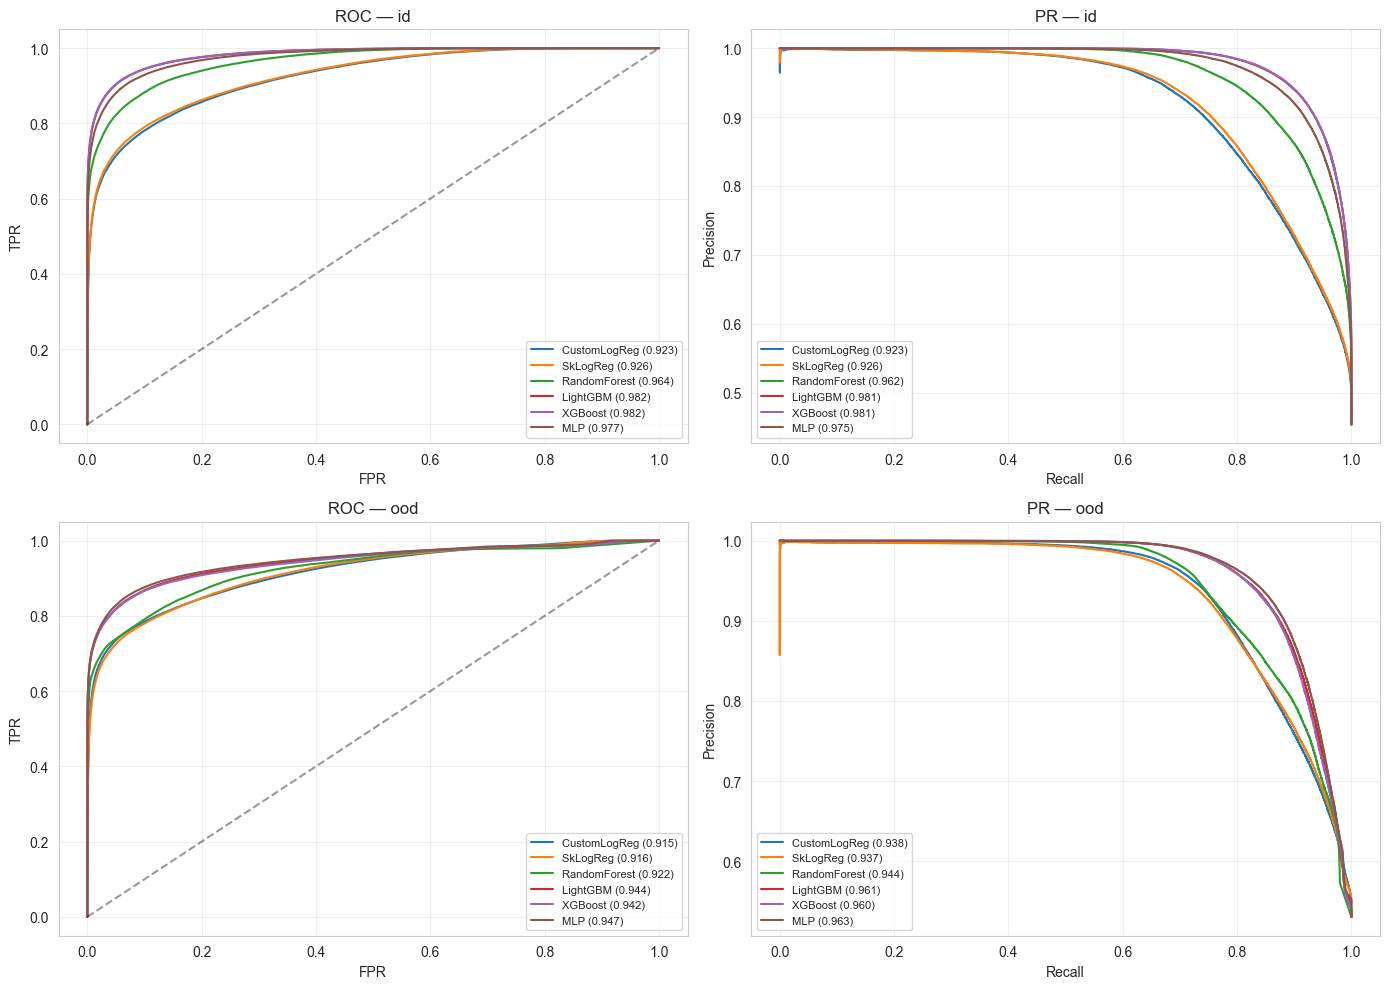

In [121]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, split in zip(axes[:, 0], ["id", "ood"]):
    y_true = y_test_id if split == "id" else y_test_ood
    for name in trained_models:
        fpr, tpr, _ = roc_curve(y_true, test_probs[split][name])
        auc = roc_auc_score(y_true, test_probs[split][name])
        ax.plot(fpr, tpr, label=f"{name} ({auc:.3f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
    ax.set_title(f"ROC — {split}")
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

for ax, split in zip(axes[:, 1], ["id", "ood"]):
    y_true = y_test_id if split == "id" else y_test_ood
    for name in trained_models:
        p, r, _ = precision_recall_curve(y_true, test_probs[split][name])
        ap = average_precision_score(y_true, test_probs[split][name])
        ax.plot(r, p, label=f"{name} ({ap:.3f})")
    ax.set_title(f"PR — {split}")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{PATHS['plots_dir']}/roc_pr_both_splits.png", dpi=140)
plt.show()

16.2

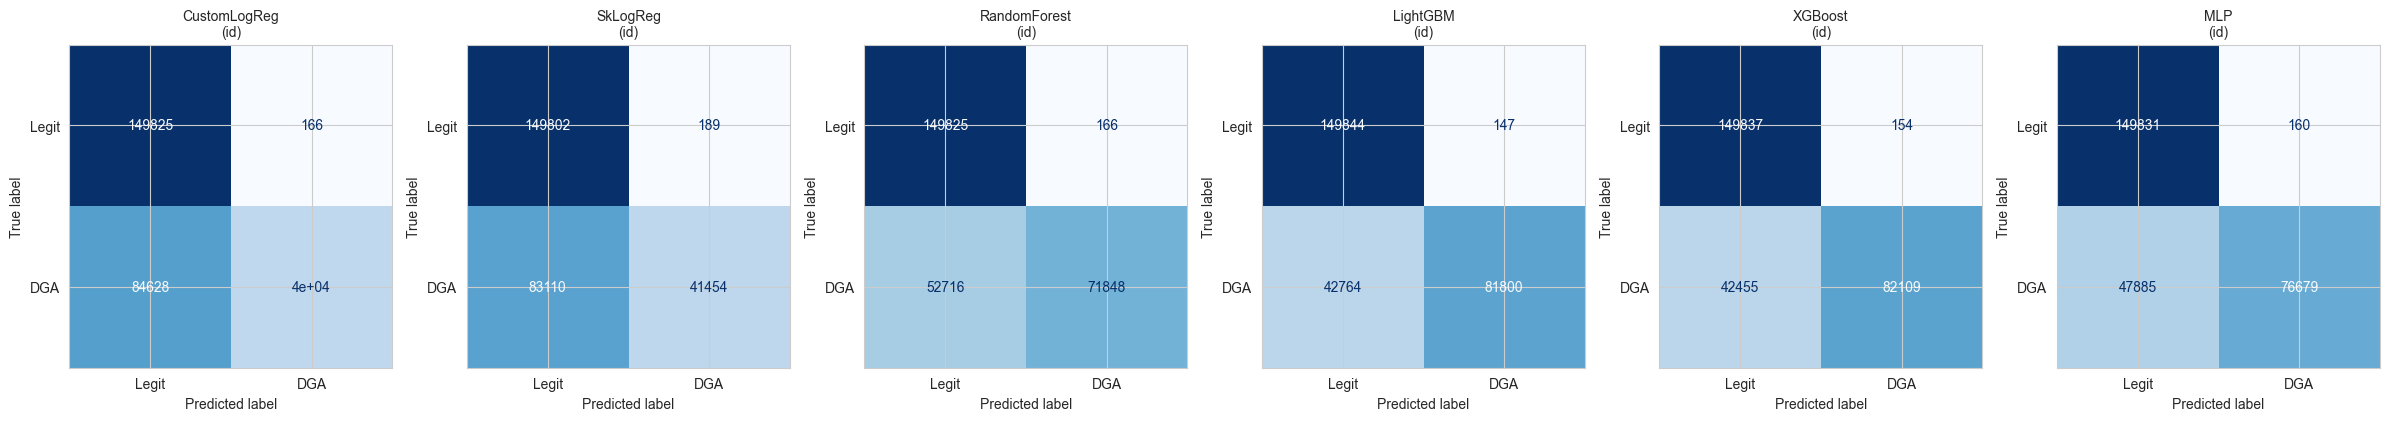

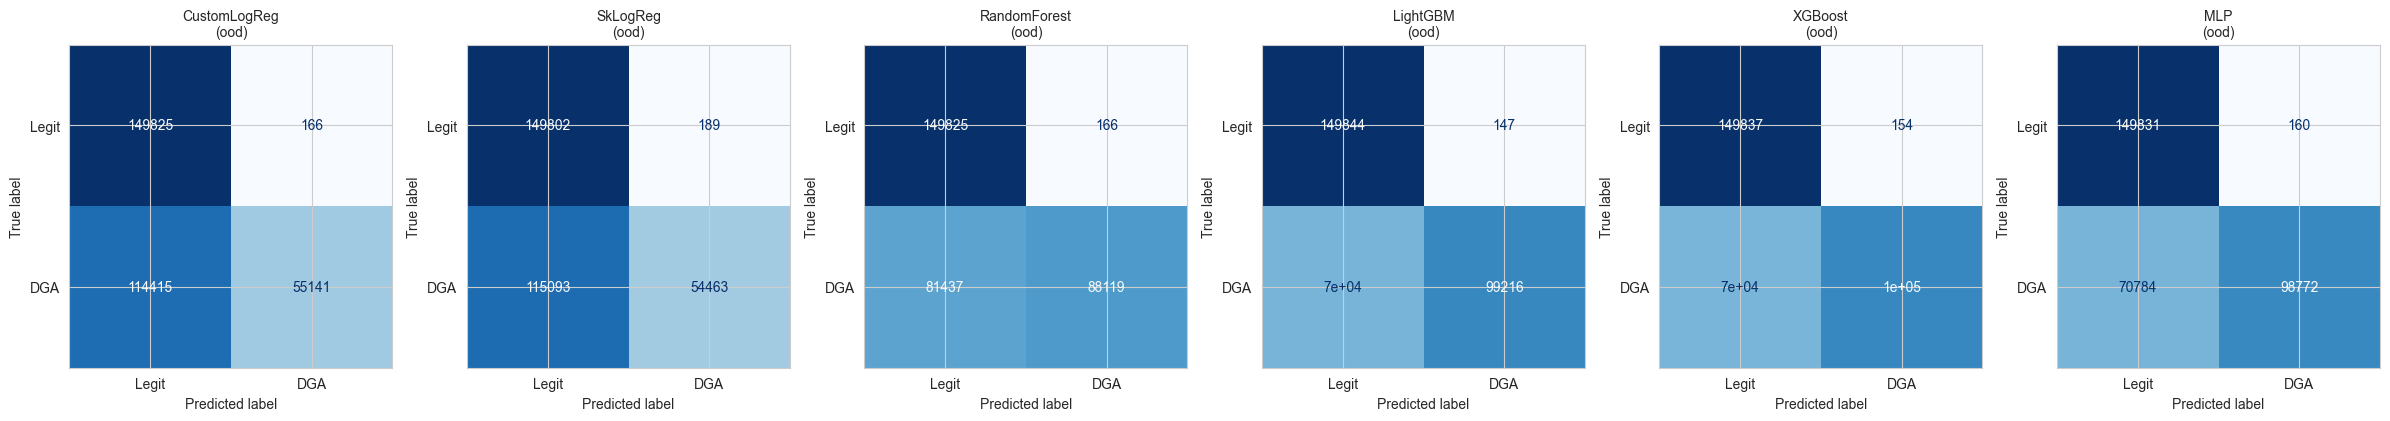

In [122]:
for split in ("id", "ood"):
    y_true = y_test_id if split == "id" else y_test_ood
    n = len(trained_models)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    for ax, name in zip(axes, trained_models):
        pred = (test_probs[split][name] >= thresholds[name]).astype(int)
        cm = confusion_matrix(y_true, pred, labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=["Legit", "DGA"]).plot(
            ax=ax, cmap="Blues", colorbar=False
        )
        ax.set_title(f"{name}\n({split})", fontsize=10)
    plt.tight_layout()
    plt.savefig(f"{PATHS['plots_dir']}/cm_{split}.png", dpi=140)
    plt.show()

16.3

In [123]:
summary = []
for name in trained_models:
    for split in ("id", "ood"):
        y_true = y_test_id if split == "id" else y_test_ood
        m = metrics_block(y_true, test_probs[split][name], thresholds[name])
        summary.append(
            {
                "model": name,
                "split": split,
                "f1": m["f1"],
                "pr_auc": m["pr_auc"],
                "tpr": m["tpr"],
                "fpr": m["fpr"],
                "fp_per_million": m["fp_per_million"],
                "tpr@fpr=1e-3": tpr_at_fpr(y_true, test_probs[split][name], 1e-3),
                "prec@prev=1e-3": precision_at_prevalence(m["tpr"], m["fpr"], 1e-3),
                "single_ms": latency[name]["single_ms"],
            }
        )

summary_df = pd.DataFrame(summary).set_index(["model", "split"])
print("=== Summary test_id vs test_ood ===")
print(summary_df.round(5).to_string())

=== Summary test_id vs test_ood ===
                         f1   pr_auc      tpr      fpr  fp_per_million  tpr@fpr=1e-3  prec@prev=1e-3  single_ms
model        split                                                                                             
CustomLogReg id     0.48505  0.92314  0.32061  0.00111      1106.73307       0.30131         0.22479    0.03528
             ood    0.49044  0.93769  0.32521  0.00111      1106.73307       0.29692         0.22729    0.03528
SkLogReg     id     0.49882  0.92598  0.33279  0.00126      1260.07560       0.30404         0.20909    0.80511
             ood    0.48583  0.93688  0.32121  0.00126      1260.07560       0.27981         0.20329    0.80511
RandomForest id     0.73099  0.96236  0.57680  0.00111      1106.73307       0.57103         0.34284   29.16186
             ood    0.68351  0.94423  0.51970  0.00111      1106.73307       0.51272         0.31975   29.16186
LightGBM     id     0.79221  0.98066  0.65669  0.00098       980.058